Feature study for the Task 2 BDT

Tests engineered features with a single training run per configuration, before deciding which to add to the main analysis in `Task_2-.ipynb`. The setup cells below are copies of Task 2's (loading, preselection, labels and the train/validation split), with `add_features()` added to `load()`. If the preselection or split changes in Task 2, change it here too.

Needs `optuna_best_params.json`, which the Optuna cell in Task 2 writes.

Setup: data loading (with the engineered features), column sorting and preselection

In [17]:
# ---------------------------------------------------------------------------------------------
# DATA SOURCES (all in MicroBooNE_data/, one pandas DataFrame per file, one row per candidate track):
#   Simulation.pkl            simulated events with NO oscillation. Has reconstructed variables (what the
#                             detector measures) AND truth columns ("Simulation ..."): true category, true
#                             neutrino energy, and a weight saying how many real events each row represents.
#                             Used to train the BDT and to build every prediction.
#   Data.pkl                  real MicroBooNE events. Reconstructed variables only - no truth, no weights
#                             (each row counts as one real event). Used only for the final fit (Task 6).
#   OscillatedSimulation.pkl  exactly the same events as Simulation.pkl, in the same order, but with weights
#                             multiplied by an oscillation probability for some chosen (Δm², sin²2θ).
#                             Used as fake data with a known answer (Task 5).
# Each event can appear as several rows ("Subevent"s = candidate tracks); the preselection keeps one.
# ---------------------------------------------------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_curve, roc_auc_score, log_loss

# Figure style for presentations: large text, thick lines and big markers, so every figure stays readable when
# pasted onto a slide at its notebook size. Individual plots only set sizes where they need something different.
plt.rcParams.update({
    "figure.figsize": (8, 5.5),
    "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 17, "figure.titlesize": 18,
    "xtick.labelsize": 15, "ytick.labelsize": 15, "legend.fontsize": 14, "legend.title_fontsize": 14,
    "lines.linewidth": 2.5, "lines.markersize": 7,
    "axes.linewidth": 1.2, "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

TOPO = "Topological muon ML score"                                          # same on every row of an event
VERTEX = [f"Interaction vertex position {a} component" for a in "xyz"]     # same on every row of an event
START = [f"Start position of lepton track {a} component" for a in "xyz"]
END = [f"End position of lepton track {a} component" for a in "xyz"]
P_RANGE = "Muon momentum (length estimate)"
P_MCS = "Muon momentum (scattering estimate)"
LENGTH = "Length of lepton track"

# MicroBooNE TPC active volume in cm (a few reconstructed points lie slightly outside)
TPC = [(0.0, 256.35), (-116.5, 116.5), (0.0, 1036.8)]   # x, y, z

# Engineered features, grouped into the batches studied in the feature study.
# (The distance from the vertex to the track start is already in the data as "Distance to longest track".)
FEATURE_BATCHES = {
    "1 vertex": ["flipped"],
    "2 containment": ["vtx_wall_dist", "start_wall_dist", "end_wall_dist", "min_end_wall", "contained"],
    "3 direction": ["cos_beam", "cos_vert"],
    "4 momentum consistency": ["p_ratio"],
    "5 event context": ["n_tracks", "len_frac", "is_longest"],
}
ENGINEERED = [f for batch in FEATURE_BATCHES.values() for f in batch]

# Short names for the BDT inputs, used on plot axes (a column not listed keeps its own name)
LABELS = {
    "Distance to closest cosmic ray track": "Distance to closest cosmic",
    "Distance to longest track": "Vertex-to-track distance",
    LENGTH: "Track length",
    TOPO: "Topological muon score",
    "Track vs shower ML score": "Track vs shower score",
    **{c: f"Vertex {a}" for c, a in zip(VERTEX, "xyz")},
    **{c: f"Track start {a}" for c, a in zip(START, "xyz")},
    **{c: f"Track end {a}" for c, a in zip(END, "xyz")},
    P_RANGE: "Muon momentum (range)",
    P_MCS: "Muon momentum (scattering)",
    "cos_beam": "cos(angle to beam)",
    "cos_vert": "cos(angle to vertical)",
    "n_tracks": "Tracks in event",
    "min_end_wall": "Nearest track end to wall",
    "start_wall_dist": "Track start to wall",
    "flipped": "Track reversed (far end at vertex)",
    "vtx_wall_dist": "Vertex to wall",
    "end_wall_dist": "Track end to wall",
    "contained": "Track contained (10 cm from walls)",
    "p_ratio": "Momentum ratio (scattering / range)",
    "len_frac": "Track length / longest in event",
    "is_longest": "Longest track in event",
}
UNITS = {**{c: "cm" for c in VERTEX + START + END + [LENGTH, "Distance to longest track",
                                                    "Distance to closest cosmic ray track", "vtx_wall_dist",
                                                    "start_wall_dist", "end_wall_dist", "min_end_wall"]},
         P_RANGE: "GeV/c", P_MCS: "GeV/c"}

def nice(f, units=False):
    """Plot label for a feature: its short name, with its units if asked."""
    name = LABELS.get(f, f)
    return f"{name} [{UNITS[f]}]" if units and f in UNITS else name

def wall_dist(points):
    """Signed distance (cm) from each point to the nearest TPC face; negative if the point is outside."""
    return np.min([np.minimum(points[:, i] - lo, hi - points[:, i]) for i, (lo, hi) in enumerate(TPC)], axis=0)

def add_features(df):
    """Add the engineered features to every row. Uses reconstructed quantities only, so it works for
    simulation, data and the oscillated set alike. Must run before preselection (event context needs
    all of an event's rows)."""
    v = df[VERTEX].to_numpy(dtype=float)
    start = df[START].to_numpy(dtype=float)
    end = df[END].to_numpy(dtype=float)
    d_start = np.linalg.norm(start - v, axis=1)
    d_end = np.linalg.norm(end - v, axis=1)

    # 1. Vertex consistency: is the track's far end the one attached to the vertex?
    flipped = d_end < d_start
    df["flipped"] = flipped.astype(int)

    # 2. Containment: distances to the nearest detector face
    df["vtx_wall_dist"] = wall_dist(v)
    df["start_wall_dist"] = wall_dist(start)
    df["end_wall_dist"] = wall_dist(end)
    df["min_end_wall"] = np.minimum(df["start_wall_dist"], df["end_wall_dist"])
    df["contained"] = (df["min_end_wall"] >= 10).astype(int)

    # 3. Direction, pointing away from the vertex (from the nearer track end to the farther one)
    near = np.where(flipped[:, None], end, start)
    far = np.where(flipped[:, None], start, end)
    seg = far - near
    seg_len = np.linalg.norm(seg, axis=1)
    seg_len = np.where(seg_len > 0, seg_len, np.nan)
    df["cos_beam"] = seg[:, 2] / seg_len     # +1 = along the beam (z)
    df["cos_vert"] = seg[:, 1] / seg_len     # +1 = straight up, -1 = straight down

    # 4. Momentum consistency: scattering / range estimate, only meaningful for contained tracks
    df["p_ratio"] = np.where(df["contained"] == 1, df[P_MCS] / df[P_RANGE], np.nan)

    # 5. Event context, computed over all rows (tracks) of each event
    g = df.groupby("event_id")[LENGTH]
    longest = g.transform("max")
    df["n_tracks"] = g.transform("size")
    df["len_frac"] = df[LENGTH] / longest
    df["is_longest"] = (df[LENGTH] == longest).astype(int)
    return df

def load(name):
    """Load one of the pickles, fix its column types, and label which rows belong to the same event."""
    df = pd.read_pickle(f"MicroBooNE_data/{name}")
    # 12 numeric columns are stored with the generic 'object' type; convert them so they can be used as numbers
    obj_cols = df.columns[df.dtypes == object]
    df[obj_cols] = df[obj_cols].astype("float32")   # numeric columns stored as generic objects
    # Rows of one event share the topological score and vertex; a new event starts when either changes.
    # The vertex is needed too, because ~17k rows have a score of exactly 0 and would merge with neighbours.
    key = df[[TOPO] + VERTEX].round(6)
    # (key != key.shift()) is True on the first row of each new event; the running total numbers the events
    df["event_id"] = (key != key.shift()).any(axis=1).cumsum()
    return add_features(df)

sim = load("Simulation.pkl")   # all simulated candidate rows (~556k rows, ~398k events), before any selection

# Column names used throughout
CAT = "Simulation category"     # true event type (simulation only): 21 = numu CC signal, 31 = NC, 10 = nue CC,
                                # 7 = EXT (beam off), 5 = outside fiducial volume, 4 = cosmic mis-ID
WGT = "Simulation weight"       # how many real events each simulated row represents (simulation only)
ENERGY = "Total energy"         # reconstructed energy in GeV - the variable whose spectrum we fit
SIGNAL = 21                     # the category we want to select: muon-neutrino charged-current
PARAMS_FILE = "optuna_best_params.json"   # where the Optuna results are saved and loaded from

In [18]:
# Split the columns into truth (only the simulation knows these), bookkeeping, and reconstructed
# variables (measured by the detector, so they also exist in real data). The BDT may only use the last group.
# Engineered features are kept separate here; cell below decides which of them to add.
truth_cols = [c for c in sim.columns if c.lower().startswith("simulat")]   # category, weight, true energy, ...
id_cols = ["Subevent", "event_id"]                                          # row/event labels, not physics
reco_cols = [c for c in sim.columns
             if c not in truth_cols and c not in id_cols and c not in ENGINEERED
             and pd.api.types.is_numeric_dtype(sim[c])]
print(reco_cols)

['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Start position of lepton track z component', 'Start position of lepton track y component', 'Start position of lepton track x component', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'Total energy', 'Muon momentum (length estimate)', 'Muon momentum (scattering estimate)']


In [19]:
def preselect(df):
    """Applied identically to simulation, data and oscillated simulation."""
    # 1. Drop events with no usable energy: ~76% of events carry a placeholder of ~10,000 GeV instead of a
    #    measured energy (the flag is the same on every row of an event, so whole events are removed)
    df = df[df[ENERGY] < 100]   # ~10,000 GeV is a placeholder flag, not a measured energy
    # 2. Keep one candidate track per event: the row with the highest Particle ID log-likelihood (most muon-like)
    best = df.groupby("event_id")["Particle ID LLh"].idxmax()   # most muon-like track in each event
    # reset_index gives rows a clean 0..n-1 index, which later cells rely on
    return df.loc[best].reset_index(drop=True)

pre = preselect(sim)   # preselected simulation: one row per event; used for BDT training and all predictions

# Bookkeeping: how much survives the preselection
events = sim.drop_duplicates("event_id")   # truth and weight are the same on every row of an event
sig_all = events.loc[events[CAT] == SIGNAL, WGT].sum()   # weighted signal events before preselection
sig_pre = pre.loc[pre[CAT] == SIGNAL, WGT].sum()         # ... and after
print(f"Candidates: {len(sim)} -> {len(pre)} (one per event)")
print(f"Events kept: {len(pre) / len(events): .1%}")
print(f"Signal kept: {sig_pre / sig_all: .1%}")

Candidates: 555624 -> 95748 (one per event)
Events kept:  24.1%
Signal kept:  45.2%


Features, labels, weights and the train/validation split (as in Task 2)

In [20]:
# Feature set the study starts from: the same as Task 2's main pipeline (Total energy left out).
# The engineered features are added on top of this by the study configurations below.
USE_ENERGY_VARS = False
energy_like = [ENERGY]

features = [c for c in reco_cols if USE_ENERGY_VARS or c not in energy_like]
print(len(features), "features:", features)

17 features: ['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Start position of lepton track z component', 'Start position of lepton track y component', 'Start position of lepton track x component', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'Muon momentum (length estimate)', 'Muon momentum (scattering estimate)']


In [21]:
# Inputs for the BDT, all built from the preselected simulation `pre` (one row per event)
pre["is_sig"] = (pre[CAT] == SIGNAL).astype(int) # 1 or 0 TRUTH column.   The answer the BDT learns: 1 = numu CC, 0 = anything else

X = pre[features].replace([np.inf, -np.inf], np.nan) # BDT doesn't handle infinities well.   Inputs: reconstructed variables only
y = pre["is_sig"]                                     # labels
w_fit = pre[WGT] / pre[WGT].mean() # rescaled to average 1.   Event weights, so the BDT learns the real beam's mix of events

In [22]:
# Split the preselected simulation into 80% training / 20% validation for the Optuna search.
# StratifiedGroupKFold keeps the signal fraction the same on both sides ("stratified") and keeps
# whole events together ("group", by event_id). We only need one of its 5 folds as the validation set.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)   # one fold of five = 20% validation
idx_train, idx_val = next(sgkf.split(X, y, groups=pre["event_id"]))

pre["split"] = "train"
pre.loc[idx_val, "split"] = "val"
print(pre["split"].value_counts())

# Boolean masks and the matching inputs/labels/weights for each side
tr = pre["split"] == "train"
va = pre["split"] == "val"
Xtr, ytr, wtr = X[tr], y[tr], w_fit[tr]
Xva, yva, wva = X[va], y[va], w_fit[va]

split
train    76598
val      19150
Name: count, dtype: int64


Hyperparameters from Task 2's Optuna run

In [23]:
# Hyperparameters tuned by Optuna in Task_2-.ipynb (saved there to PARAMS_FILE).
# Every configuration in this study uses the same settings, so differences come from the features.
with open(PARAMS_FILE) as f:
    saved = json.load(f)
best_params = saved["params"]
print(f"Loaded {PARAMS_FILE} (saved {saved['saved']}, {saved['n_trials']} trials, "
      f"validation AUC {saved['best_val_auc']:.4f})")
if saved["features"] != features:
    print("WARNING: these hyperparameters were tuned with a different feature list - re-run Optuna in Task 2")

Loaded optuna_best_params.json (saved 2026-10-21T15:41:21, 100 trials, validation AUC 0.8830)


Feature study (single training run, not part of the main pipeline)

Tests the engineered features before committing to them. Every configuration is trained the same way: the same hyperparameters (`best_params`), trained on the training split with 10% of it held back for early stopping (1-SE tree count), and evaluated on the validation split only. Each configuration is trained with several random seeds, so differences smaller than the seed-to-seed spread can be ignored. Differences relative to the baseline get uncertainties from a paired bootstrap of the validation events.

Run these cells in order after the hyperparameter-loading cell. The main pipeline is unaffected until features are added to `ENGINEERED_KEEP`.

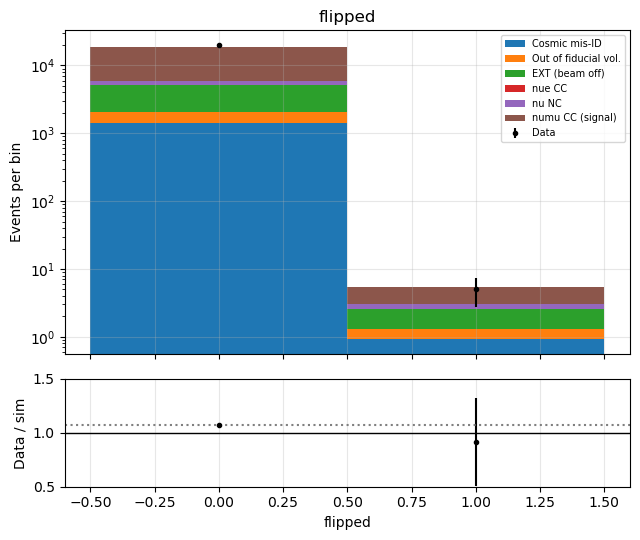

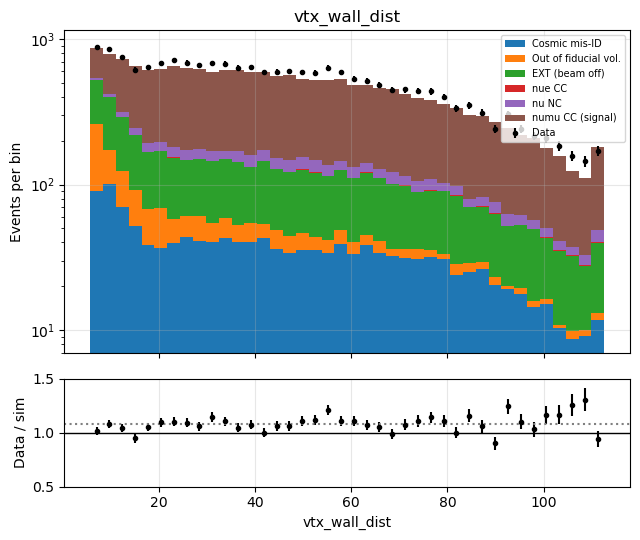

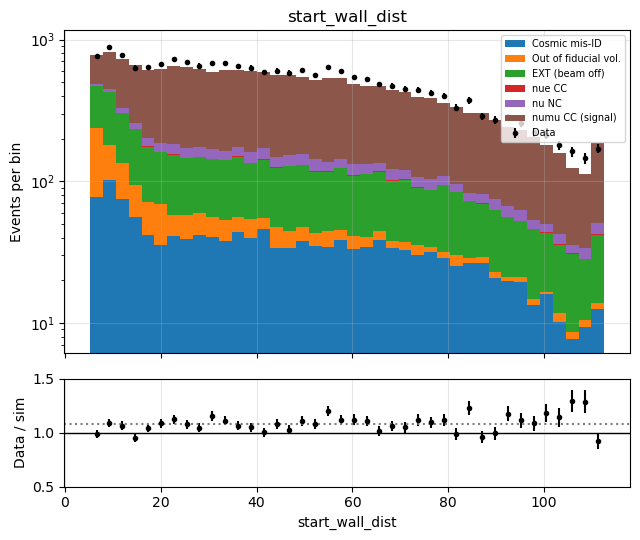

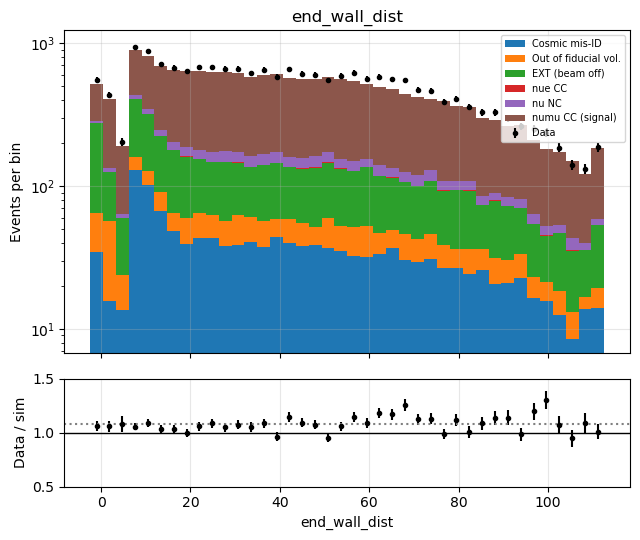

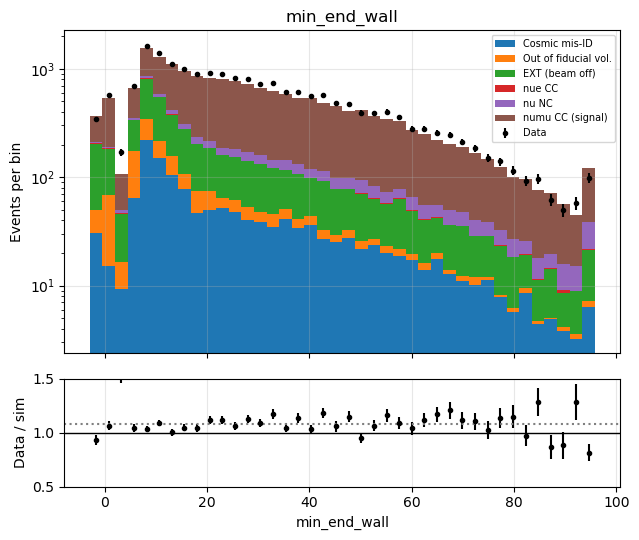

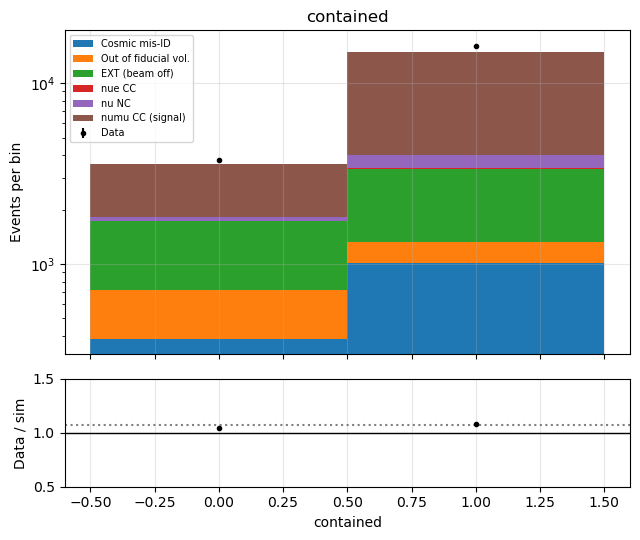

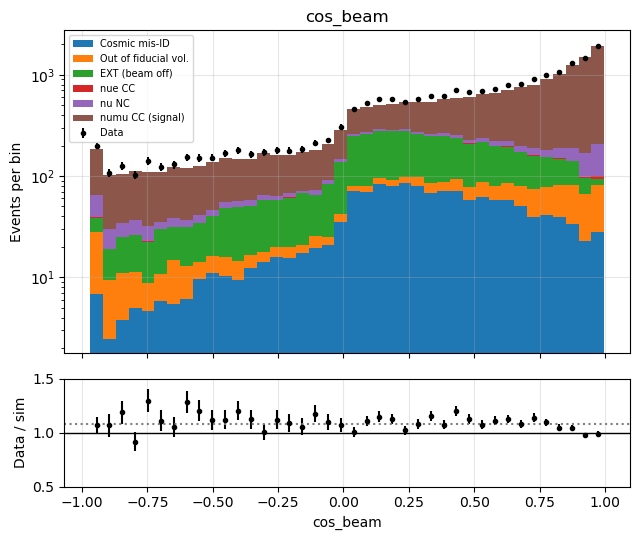

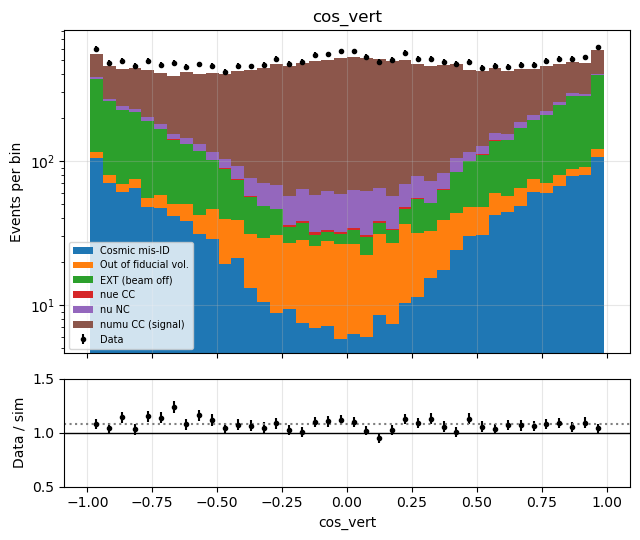

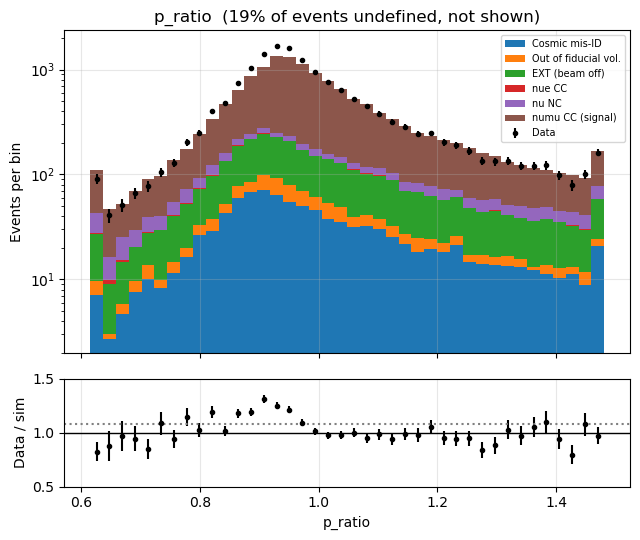

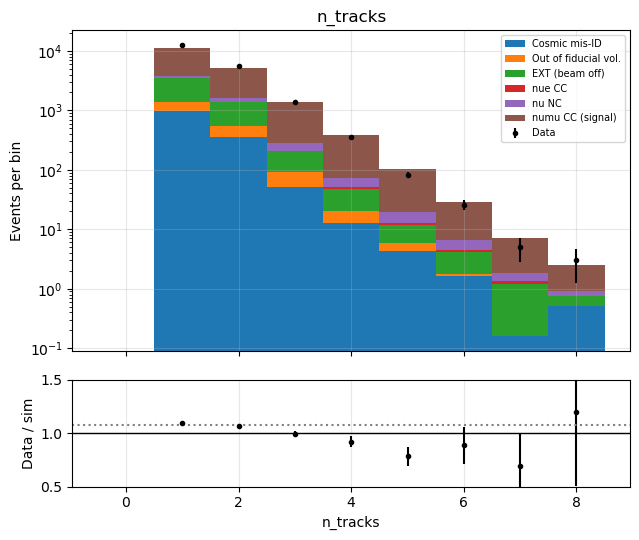

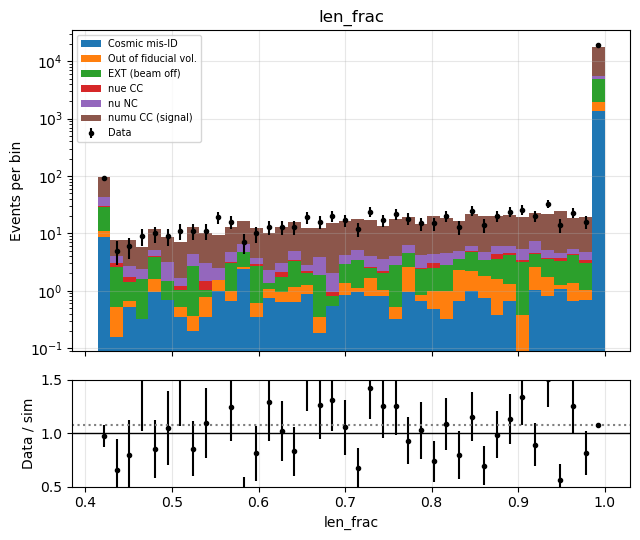

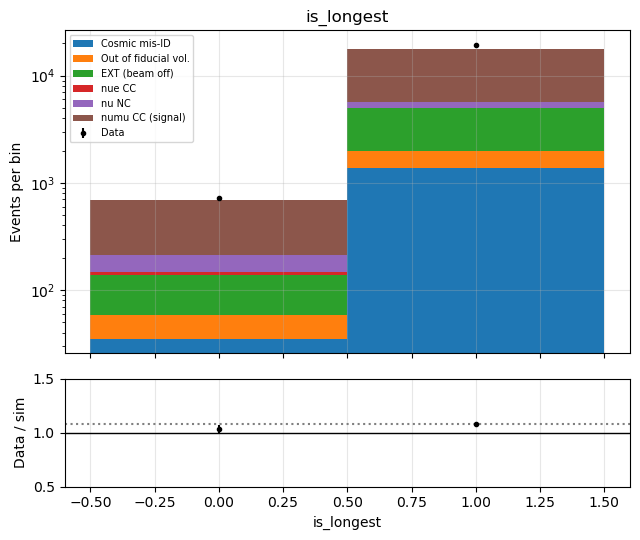

In [24]:
# Data vs simulation for each engineered feature (preselected events, before any BDT cut).
# A feature is only trustworthy if the simulation describes it: look for a roughly flat data/simulation ratio.
data_fs = preselect(load("Data.pkl"))
fs_names = {21: "numu CC (signal)", 31: "nu NC", 10: "nue CC", 7: "EXT (beam off)",
            5: "Out of fiducial vol.", 4: "Cosmic mis-ID"}
fs_labels = {21: r"$\nu_\mu$ CC (signal)", 31: r"$\nu$ NC", 10: r"$\nu_e$ CC", 7: "EXT (beam off)",
             5: "Out of fiducial vol.", 4: "Cosmic mis-ID"}   # the same names, formatted for plots
fs_order = [4, 5, 7, 10, 31, 21]
DISCRETE = ["flipped", "contained", "is_longest", "n_tracks"]
BINARY = ["flipped", "contained", "is_longest"]   # 0/1 features: x axis labelled No/Yes

def plot_data_vs_sim(feat):
    """Preselected simulation stacked by true category, real data on top, and their ratio."""
    sim_vals, dat_vals = pre[feat].to_numpy(dtype=float), data_fs[feat].to_numpy(dtype=float)
    ok_sim, ok_dat = np.isfinite(sim_vals), np.isfinite(dat_vals)
    if feat in DISCRETE:
        top = min(int(np.nanmax(sim_vals)), 8)
        edges = np.arange(-0.5, top + 1.5)
        sim_vals, dat_vals = np.minimum(sim_vals, top), np.minimum(dat_vals, top)   # last bin = overflow
    else:
        lo, hi = np.nanquantile(sim_vals, [0.005, 0.995])
        edges = np.linspace(lo, hi, 41)
        sim_vals, dat_vals = np.clip(sim_vals, lo, hi), np.clip(dat_vals, lo, hi)   # end bins include the tails
    centres = (edges[:-1] + edges[1:]) / 2

    fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10.5, 6.5), gridspec_kw={"height_ratios": [3, 1]})
    parts = [ok_sim & (pre[CAT].to_numpy() == c) for c in fs_order]
    ax1.hist([sim_vals[m] for m in parts], bins=edges, weights=[pre[WGT].to_numpy()[m] for m in parts],
             stacked=True, label=[fs_labels[c] for c in fs_order])
    sim_total, _ = np.histogram(sim_vals[ok_sim], bins=edges, weights=pre[WGT].to_numpy()[ok_sim])
    dat_counts, _ = np.histogram(dat_vals[ok_dat], bins=edges)
    ax1.errorbar(centres, dat_counts, yerr=np.sqrt(dat_counts), fmt="ko", markersize=5, label="Data")
    ax1.set_yscale("log")
    ax1.set_ylabel("Events per bin")
    missing = 1 - ok_sim.mean()
    ax1.set_title(nice(feat) + (f"\n({missing:.0%} of events undefined, not shown)" if missing > 0 else ""))
    ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1))   # outside the plot, so it covers no data

    ratio = np.divide(dat_counts, sim_total, out=np.full_like(sim_total, np.nan), where=sim_total > 0)
    ratio_err = np.divide(np.sqrt(dat_counts), sim_total, out=np.full_like(sim_total, np.nan), where=sim_total > 0)
    ax2.errorbar(centres, ratio, yerr=ratio_err, fmt="ko", markersize=5)
    ax2.axhline(1, color="black", lw=1)
    ax2.axhline(dat_counts.sum() / sim_total.sum(), color="grey", ls=":", lw=2, label="Overall data / sim.")
    ax2.set_ylim(0.5, 1.5)
    ax2.set_ylabel("Data / sim.")
    ax2.set_xlabel(nice(feat, units=True))
    ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    if feat in BINARY:
        ax2.set_xticks([0, 1], ["No", "Yes"])
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

for feat in ENGINEERED:
    plot_data_vs_sim(feat)

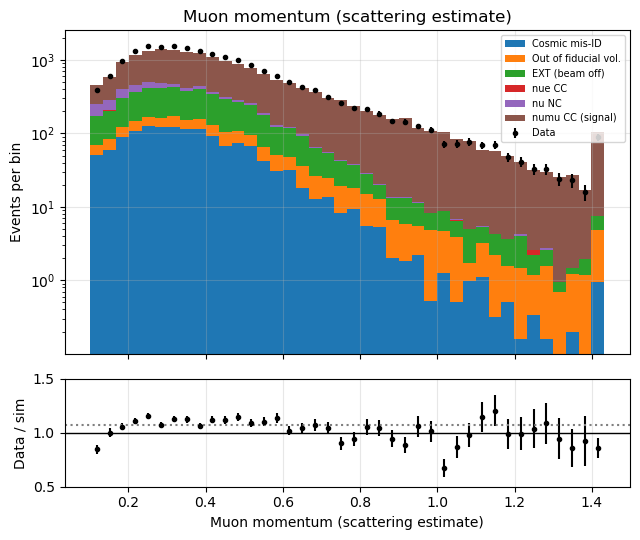

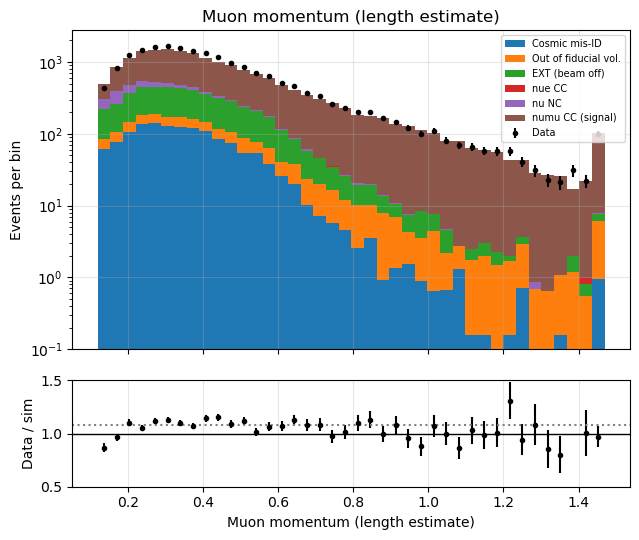

In [25]:
# The two original muon momentum estimates, data vs simulation. p_ratio (scattering / range) was
# mismodelled at its peak; the range estimate is a fixed function of track length, so if the
# mismodelling is real it should show up here in the scattering estimate.
for feat in [P_MCS, P_RANGE]:
    plot_data_vs_sim(feat)

,chi2,ndf,chi2/ndf,largest deviation in busy bins,undefined (data),undefined (sim),engineered
flipped,0,1,0.13,0.0%,0.0%,0.0%,True
cos_vert,34,39,0.86,14.7%,0.0%,0.0%,True
Track vs shower ML score,36,39,0.92,6.1%,0.0%,0.0%,False
Distance to closest cosmic ray track,38,39,0.99,11.2%,0.0%,0.0%,False
is_longest,1,1,1.15,4.2%,0.0%,0.0%,True
len_frac,46,39,1.19,0.2%,0.0%,0.0%,True
End position of lepton track x component,47,39,1.21,12.9%,0.0%,0.0%,False
Particle ID LLh,47,39,1.21,12.4%,0.0%,0.0%,False
Start position of lepton track y component,47,39,1.21,13.0%,0.0%,0.0%,False
Start position of lepton track x component,47,39,1.22,12.3%,0.0%,0.0%,False


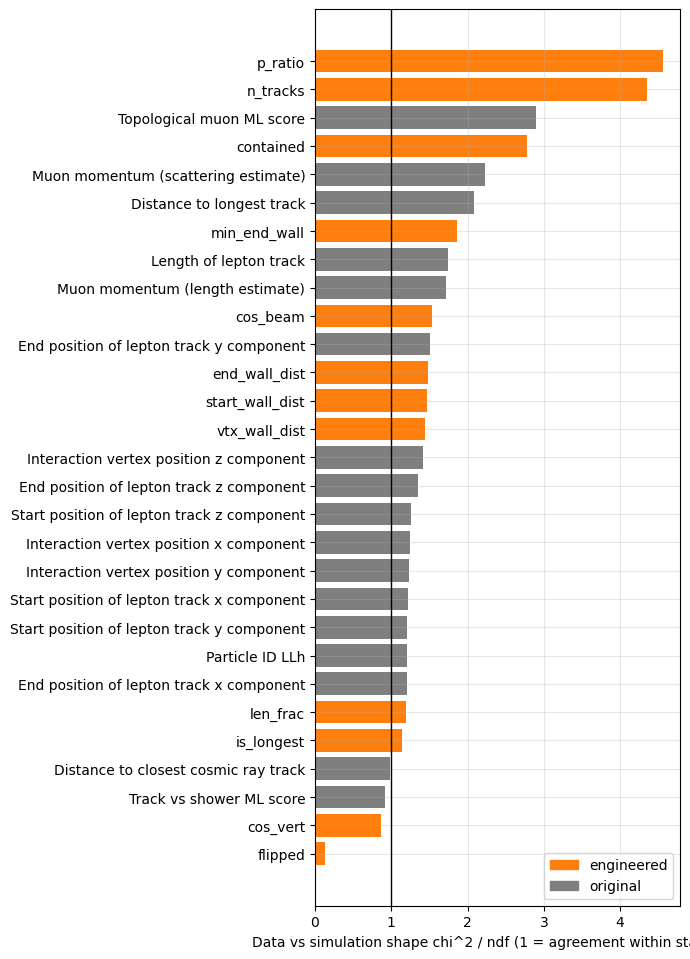

In [38]:
# How well does the simulation model each feature? For every feature, histogram preselected data and
# simulation in the same bins as the plots above, scale the simulation to the data total (so the ~8%
# normalisation difference drops out), and compute a shape chi^2:
#   chi2 = sum (data - k*sim)^2 / (data + k^2 * sum w^2),   ndf = bins - 1
# chi2/ndf ~ 1: shapes agree within statistics. Much larger: a real shape difference. With thousands of events
# per bin even small differences become significant, so also look at the size of the deviation in busy bins.
def shape_chi2(feat, n_bins=40):
    sim_vals, dat_vals = pre[feat].to_numpy(dtype=float), data_fs[feat].to_numpy(dtype=float)
    ok_sim, ok_dat = np.isfinite(sim_vals), np.isfinite(dat_vals)
    w = pre[WGT].to_numpy()
    if feat in DISCRETE:
        top = min(int(np.nanmax(sim_vals)), 8)
        edges = np.arange(-0.5, top + 1.5)
        sim_vals, dat_vals = np.minimum(sim_vals, top), np.minimum(dat_vals, top)
    else:
        lo, hi = np.nanquantile(sim_vals, [0.005, 0.995])
        edges = np.linspace(lo, hi, n_bins + 1)
        sim_vals, dat_vals = np.clip(sim_vals, lo, hi), np.clip(dat_vals, lo, hi)
    hs, _ = np.histogram(sim_vals[ok_sim], bins=edges, weights=w[ok_sim])
    hs2, _ = np.histogram(sim_vals[ok_sim], bins=edges, weights=w[ok_sim] ** 2)
    hd, _ = np.histogram(dat_vals[ok_dat], bins=edges)
    k = hd.sum() / hs.sum()
    var = hd + k ** 2 * hs2
    ok = var > 0
    chi2 = np.sum((hd - k * hs)[ok] ** 2 / var[ok])
    ndf = ok.sum() - 1
    busy = ok & (hd >= 0.02 * hd.sum())                          # bins holding at least 2% of the data
    dev = np.abs(hd[busy] / (k * hs[busy]) - 1).max() if busy.any() else np.nan
    return {"chi2": chi2, "ndf": ndf, "chi2/ndf": chi2 / ndf, "largest deviation in busy bins": dev,
            "undefined (data)": 1 - ok_dat.mean(), "undefined (sim)": 1 - np.average(ok_sim, weights=w),
            "engineered": feat in ENGINEERED}

all_feats = list(dict.fromkeys(features + [P_RANGE, P_MCS] + ENGINEERED))   # original features + every engineered one
chi2_table = pd.DataFrame({f: shape_chi2(f) for f in all_feats}).T.sort_values("chi2/ndf")
display(chi2_table.style.format({"chi2": "{:.0f}", "ndf": "{:.0f}", "chi2/ndf": "{:.2f}",
                                 "largest deviation in busy bins": "{:.1%}", "undefined (data)": "{:.1%}",
                                 "undefined (sim)": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, eng, title, colour in [(axes[0], False, "Original variables", "tab:grey"),
                               (axes[1], True, "Engineered features", "tab:orange")]:
    t = chi2_table[chi2_table["engineered"] == eng]
    ax.barh([nice(f) for f in t.index], t["chi2/ndf"], color=colour)
    ax.axvline(1, color="black", lw=1.5)
    ax.set_xlabel(r"Data vs simulation shape $\chi^2$/ndf")
    ax.set_title(title)
    ax.grid(alpha=0.3)
fig.suptitle(r"Shape agreement of each feature ($\chi^2$/ndf = 1: agreement within statistics)")
plt.tight_layout()
plt.show()

In [9]:
# The evaluation harness: one function trains a configuration, one computes every metric.
FS_SEEDS = (1, 2, 3)       # random seeds per configuration; differences below the seed spread are noise
FS_EFFS = (0.90, 0.94)     # signal efficiencies at which background rejection is compared
FS_N_BOOT = 200            # bootstrap resamples for the uncertainties on differences from the baseline
FS_SE_SCALE = 1.0          # 1-SE tree choice, as in the k-fold
LOW_E = 0.5                # GeV: "low-energy" signal efficiency is measured below this

# Training split -> 90% fit + 10% early stopping (whole events); the validation split is only for measuring
fs_train_all = np.flatnonzero(tr.to_numpy())
fs_val = np.flatnonzero(va.to_numpy())
fs_gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=0)
r_fit, r_es = next(fs_gss.split(fs_train_all, groups=pre["event_id"].to_numpy()[fs_train_all]))
fs_fit, fs_es = fs_train_all[r_fit], fs_train_all[r_es]

y_all, wfit_all = y.to_numpy(), w_fit.to_numpy()
y_val = y_all[fs_val]
w_val = pre[WGT].to_numpy()[fs_val]
cat_val = pre[CAT].to_numpy()[fs_val]
E_val = pre[ENERGY].to_numpy()[fs_val]
BKG_CATS = [c for c in fs_order if c != SIGNAL]

# The same bootstrap resamples are used for every configuration, so differences are paired
fs_rng = np.random.default_rng(0)
FS_BOOT = [fs_rng.integers(0, len(fs_val), len(fs_val)) for _ in range(FS_N_BOOT)]

def fs_train(feats, seed):
    """Train one model on the given features; return its validation scores, tree count and the model."""
    Xf = pre[feats].replace([np.inf, -np.inf], np.nan)
    m = xgboost.XGBClassifier(**best_params, n_estimators=3000, early_stopping_rounds=50,
                              eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=seed)
    m.fit(Xf.iloc[fs_fit], y_all[fs_fit], sample_weight=wfit_all[fs_fit],
          eval_set=[(Xf.iloc[fs_es], y_all[fs_es])], sample_weight_eval_set=[wfit_all[fs_es]],
          verbose=False)
    # 1-SE tree count from the early-stopping curve (same rule as the k-fold)
    curve = np.array(m.evals_result_["validation_0"]["logloss"])
    best = curve.argmin()
    p = np.clip(m.predict_proba(Xf.iloc[fs_es], iteration_range=(0, best + 1))[:, 1], 1e-15, 1 - 1e-15)
    yy, ww = y_all[fs_es], wfit_all[fs_es]
    per_event = -(yy * np.log(p) + (1 - yy) * np.log(1 - p))
    L = np.average(per_event, weights=ww)
    se = np.sqrt(np.sum(ww**2 * (per_event - L)**2)) / ww.sum()
    n = int(np.argmax(curve <= curve[best] + FS_SE_SCALE * se)) + 1
    return m.predict_proba(Xf.iloc[fs_val], iteration_range=(0, n))[:, 1], n, m

def fs_metrics(score, idx=None):
    """Every metric on the validation events (or on a bootstrap resample of them, given by idx)."""
    s, yy, ww, cc, ee = (score, y_val, w_val, cat_val, E_val) if idx is None else \
                        (score[idx], y_val[idx], w_val[idx], cat_val[idx], E_val[idx])
    sig = yy == 1
    out = {"AUC": roc_auc_score(yy, s, sample_weight=ww),
           "log loss": log_loss(yy, np.clip(s, 1e-15, 1 - 1e-15), sample_weight=ww)}
    for c in BKG_CATS:                          # signal vs one background at a time
        m = sig | (cc == c)
        out[f"AUC vs {fs_names[c]}"] = roc_auc_score(yy[m], s[m], sample_weight=ww[m])
    for eff in FS_EFFS:
        # threshold that keeps exactly this fraction of the (weighted) signal
        order = np.argsort(-s[sig])
        cum = np.cumsum(ww[sig][order]) / ww[sig].sum()
        thr = s[sig][order][min(np.searchsorted(cum, eff), sig.sum() - 1)]
        passed = s >= thr
        out[f"background kept @{eff:.0%}"] = ww[passed & ~sig].sum() / ww[~sig].sum()
        out[f"purity @{eff:.0%}"] = ww[passed & sig].sum() / ww[passed].sum()
        for c in fs_order:
            m = cc == c
            out[f"{fs_names[c]} kept @{eff:.0%}"] = ww[passed & m].sum() / ww[m].sum()
        low = sig & (ee < LOW_E)
        out[f"signal eff E<{LOW_E} GeV @{eff:.0%}"] = ww[passed & low].sum() / ww[low].sum()
    return out

fs_results = {}   # configuration name -> results; re-running a configuration reuses its stored result

def run_config(name, feats):
    """Train a configuration with every seed, store its metrics, and print a one-line summary."""
    key = tuple(feats)
    for other, res in fs_results.items():
        if res["key"] == key:
            print(f"{name}: same features as '{other}', reusing")
            fs_results[name] = res
            return res
    scores, trees, models_seed = [], [], []
    for seed in FS_SEEDS:
        sc, n, m = fs_train(list(feats), seed)
        scores.append(sc); trees.append(n); models_seed.append(m)
    per_seed = pd.DataFrame([fs_metrics(sc) for sc in scores])
    fs_results[name] = {"key": key, "features": list(feats), "scores": scores, "trees": trees,
                        "per_seed": per_seed, "model": models_seed[0]}
    print(f"{name}: {len(feats)} features, trees {trees}, AUC {per_seed['AUC'].mean():.4f} "
          f"± {per_seed['AUC'].std():.4f} (seed spread)")
    return fs_results[name]

fs_boot_cache = {}   # feature set -> metrics on every bootstrap resample (first seed)

def boot_metrics(name):
    key = fs_results[name]["key"]
    if key not in fs_boot_cache:
        s = fs_results[name]["scores"][0]
        fs_boot_cache[key] = pd.DataFrame([fs_metrics(s, idx) for idx in FS_BOOT])
    return fs_boot_cache[key]

def paired_delta(name, base="baseline"):
    """Bootstrap uncertainty on (configuration - baseline) for every metric, using each one's first seed.
    Both are evaluated on the same resampled events, so most of the noise cancels in the difference."""
    return (boot_metrics(name) - boot_metrics(base)).std()

In [10]:
# Configurations: the baseline, then each batch added cumulatively, then "everything minus one batch"
# (ablation), and "everything without the muon momentum estimates" (the low-energy efficiency question).
# To test something else, call run_config("my name", BASE + ["cos_vert"]) in a new cell.
BASE = [f for f in features if f not in ENGINEERED]   # the original feature set
MOMENTUM = [P_RANGE, P_MCS]

CONFIGS = {"baseline": BASE}
cumulative = list(BASE)
for batch_name, batch in FEATURE_BATCHES.items():
    cumulative = cumulative + batch
    CONFIGS[f"+ {batch_name}"] = list(cumulative)
ALL = list(cumulative)
for batch_name, batch in FEATURE_BATCHES.items():
    CONFIGS[f"all - {batch_name}"] = [f for f in ALL if f not in batch]
CONFIGS["all - momentum estimates"] = [f for f in ALL if f not in MOMENTUM]

# Which configurations to run now (each takes roughly len(FS_SEEDS) training runs).
# Start with the cumulative batches; add the ablation names afterwards if wanted.
RUN = ["baseline"] + [f"+ {b}" for b in FEATURE_BATCHES]
for name in RUN:
    if name not in fs_results:
        run_config(name, CONFIGS[name])

baseline: 17 features, trees [549, 560, 617], AUC 0.8785 ± 0.0003 (seed spread)
+ 1 vertex: 18 features, trees [604, 549, 604], AUC 0.8782 ± 0.0004 (seed spread)
+ 2 containment: 23 features, trees [529, 594, 539], AUC 0.8788 ± 0.0003 (seed spread)
+ 3 direction: 25 features, trees [453, 456, 495], AUC 0.8866 ± 0.0004 (seed spread)
+ 4 momentum consistency: 26 features, trees [464, 463, 477], AUC 0.8871 ± 0.0001 (seed spread)
+ 5 event context: 29 features, trees [471, 488, 488], AUC 0.8891 ± 0.0003 (seed spread)


In [11]:
# Ablation and the "no momentum estimates" variant (run after the cell above)
RUN_ABLATION = [f"all - {b}" for b in FEATURE_BATCHES] + ["all - momentum estimates"]
for name in RUN_ABLATION:
    if name not in fs_results:
        run_config(name, CONFIGS[name])

all - 1 vertex: 28 features, trees [520, 443, 535], AUC 0.8895 ± 0.0007 (seed spread)
all - 2 containment: 24 features, trees [496, 511, 524], AUC 0.8890 ± 0.0001 (seed spread)
all - 3 direction: 27 features, trees [542, 558, 595], AUC 0.8814 ± 0.0003 (seed spread)
all - 4 momentum consistency: 28 features, trees [461, 486, 490], AUC 0.8886 ± 0.0003 (seed spread)
all - 5 event context: same features as '+ 4 momentum consistency', reusing
all - momentum estimates: 27 features, trees [544, 494, 485], AUC 0.8895 ± 0.0003 (seed spread)


In [12]:
# Explicit momentum tests: do the energy-like features shape the selection's energy dependence?
# The range momentum is computed from the track length, so removing only the momenta leaves that
# information in the BDT; the second configuration removes the track length as well.
MOMENTUM_TESTS = {
    "baseline - momenta + p_ratio": [f for f in BASE if f not in MOMENTUM] + ["p_ratio"],   # isolated swap
    "all - energy-like": [f for f in ALL if f not in MOMENTUM + [LENGTH]],                 # momenta and length out
}
for name, feats in MOMENTUM_TESTS.items():
    if name not in fs_results:
        run_config(name, feats)

baseline - momenta + p_ratio: 16 features, trees [529, 545, 511], AUC 0.8789 ± 0.0002 (seed spread)
all - energy-like: 26 features, trees [419, 455, 448], AUC 0.8875 ± 0.0002 (seed spread)


In [26]:
# Compact set: original features without the two momentum estimates, plus the direction features
# and the number of tracks (the engineered features that clearly helped and are well modelled)
COMPACT = [f for f in BASE if f not in MOMENTUM] + ["cos_beam", "cos_vert", "n_tracks"]
run_config("compact", COMPACT);   # the semicolon stops Jupyter printing the returned results

compact: 18 features, trees [477, 502, 507], AUC 0.8877 ± 0.0001 (seed spread)


{'key': ('Distance to closest cosmic ray track',
  'Length of lepton track',
  'Distance to longest track',
  'Topological muon ML score',
  'End position of lepton track z component',
  'End position of lepton track y component',
  'End position of lepton track x component',
  'Track vs shower ML score',
  'Particle ID LLh',
  'Start position of lepton track z component',
  'Start position of lepton track y component',
  'Start position of lepton track x component',
  'Interaction vertex position x component',
  'Interaction vertex position y component',
  'Interaction vertex position z component',
  'cos_beam',
  'cos_vert',
  'n_tracks'),
 'features': ['Distance to closest cosmic ray track',
  'Length of lepton track',
  'Distance to longest track',
  'Topological muon ML score',
  'End position of lepton track z component',
  'End position of lepton track y component',
  'End position of lepton track x component',
  'Track vs shower ML score',
  'Particle ID LLh',
  'Start position

In [27]:
# Compact set plus the two containment features that had some importance (helps out-of-volume events)
run_config("compact + containment", COMPACT + ["min_end_wall", "start_wall_dist"]);   # the semicolon stops Jupyter printing the returned results

compact + containment: 20 features, trees [454, 492, 479], AUC 0.8885 ± 0.0002 (seed spread)


{'key': ('Distance to closest cosmic ray track',
  'Length of lepton track',
  'Distance to longest track',
  'Topological muon ML score',
  'End position of lepton track z component',
  'End position of lepton track y component',
  'End position of lepton track x component',
  'Track vs shower ML score',
  'Particle ID LLh',
  'Start position of lepton track z component',
  'Start position of lepton track y component',
  'Start position of lepton track x component',
  'Interaction vertex position x component',
  'Interaction vertex position y component',
  'Interaction vertex position z component',
  'cos_beam',
  'cos_vert',
  'n_tracks',
  'min_end_wall',
  'start_wall_dist'),
 'features': ['Distance to closest cosmic ray track',
  'Length of lepton track',
  'Distance to longest track',
  'Topological muon ML score',
  'End position of lepton track z component',
  'End position of lepton track y component',
  'End position of lepton track x component',
  'Track vs shower ML score',

Weighted validation events per category: {'Cosmic mis-ID': 283.0, 'Out of fiducial vol.': 119.7, 'EXT (beam off)': 610.6, 'nue CC': 6.2, 'nu NC': 147.5, 'numu CC (signal)': 2500.6}
Overall


,features,trees (mean),AUC,AUC seed spread,Δ AUC,Δ log loss,Δ background kept @94%,Δ signal eff E<0.5 GeV @94%
configuration,,,,,,,,
baseline,17,575,0.8785,0.0003,NaN,NaN,NaN,NaN
+ 1 vertex,18,585,0.8782,0.0004,-0.0002 ± 0.0002,+0.0004 ± 0.0003,-0.0001 ± 0.0047,-0.0014 ± 0.0028
+ 2 containment,23,554,0.8788,0.0003,+0.0004 ± 0.0004,-0.0010 ± 0.0006,-0.0074 ± 0.0036,-0.0023 ± 0.0032
+ 3 direction,25,468,0.8866,0.0004,+0.0082 ± 0.0008,-0.0109 ± 0.0010,-0.0208 ± 0.0065,-0.0088 ± 0.0040
+ 4 momentum consistency,26,468,0.8871,0.0001,+0.0086 ± 0.0008,-0.0116 ± 0.0011,-0.0198 ± 0.0071,-0.0074 ± 0.0039
+ 5 event context,29,482,0.8891,0.0003,+0.0106 ± 0.0008,-0.0148 ± 0.0011,-0.0253 ± 0.0080,-0.0066 ± 0.0040
all - 1 vertex,28,499,0.8895,0.0007,+0.0111 ± 0.0008,-0.0156 ± 0.0011,-0.0258 ± 0.0057,-0.0057 ± 0.0038
all - 2 containment,24,510,0.8890,0.0001,+0.0105 ± 0.0008,-0.0145 ± 0.0011,-0.0267 ± 0.0061,-0.0041 ± 0.0035
all - 3 direction,27,565,0.8814,0.0003,+0.0029 ± 0.0006,-0.0048 ± 0.0008,-0.0105 ± 0.0051,-0.0046 ± 0.0035


Fraction of each background kept at 90% signal efficiency (baseline: value; others: change)


,Cosmic mis-ID,Out of fiducial vol.,EXT (beam off),nue CC,nu NC,purity
configuration,,,,,,
baseline,0.300,0.558,0.209,0.810,0.796,0.849
+ 1 vertex,-0.001 ± 0.004,+0.003 ± 0.007,-0.000 ± 0.004,-0.000 ± 0.000,-0.000 ± 0.005,0.849
+ 2 containment,-0.002 ± 0.005,-0.014 ± 0.010,+0.004 ± 0.005,-0.000 ± 0.000,+0.001 ± 0.006,0.849
+ 3 direction,-0.018 ± 0.008,-0.052 ± 0.016,-0.010 ± 0.007,+0.017 ± 0.026,-0.014 ± 0.008,0.855
+ 4 momentum consistency,-0.011 ± 0.008,-0.040 ± 0.016,-0.010 ± 0.007,+0.026 ± 0.026,-0.016 ± 0.009,0.854
+ 5 event context,-0.023 ± 0.009,-0.039 ± 0.017,-0.010 ± 0.007,+0.026 ± 0.026,-0.014 ± 0.009,0.855
all - 1 vertex,-0.021 ± 0.008,-0.037 ± 0.016,-0.011 ± 0.007,+0.026 ± 0.026,-0.012 ± 0.009,0.855
all - 2 containment,-0.021 ± 0.008,-0.024 ± 0.016,-0.015 ± 0.007,+0.026 ± 0.026,-0.013 ± 0.010,0.855
all - 3 direction,-0.017 ± 0.009,-0.006 ± 0.012,-0.010 ± 0.006,+0.017 ± 0.036,-0.009 ± 0.008,0.853


Fraction of each background kept at 94% signal efficiency (baseline: value; others: change)


,Cosmic mis-ID,Out of fiducial vol.,EXT (beam off),nue CC,nu NC,purity
configuration,,,,,,
baseline,0.392,0.674,0.313,0.844,0.861,0.820
+ 1 vertex,-0.002 ± 0.005,+0.006 ± 0.008,-0.000 ± 0.006,+0.017 ± 0.025,-0.001 ± 0.005,0.820
+ 2 containment,-0.003 ± 0.007,-0.028 ± 0.010,-0.007 ± 0.005,+0.009 ± 0.000,-0.003 ± 0.006,0.823
+ 3 direction,-0.022 ± 0.008,-0.050 ± 0.019,-0.020 ± 0.008,-0.009 ± 0.000,+0.001 ± 0.007,0.827
+ 4 momentum consistency,-0.018 ± 0.010,-0.036 ± 0.018,-0.023 ± 0.008,+0.009 ± 0.026,+0.003 ± 0.008,0.827
+ 5 event context,-0.027 ± 0.009,-0.052 ± 0.021,-0.024 ± 0.009,+0.000 ± 0.025,-0.005 ± 0.008,0.829
all - 1 vertex,-0.024 ± 0.010,-0.048 ± 0.018,-0.028 ± 0.007,-0.009 ± 0.000,-0.003 ± 0.008,0.829
all - 2 containment,-0.033 ± 0.009,-0.036 ± 0.016,-0.028 ± 0.007,+0.028 ± 0.038,-0.004 ± 0.009,0.829
all - 3 direction,-0.008 ± 0.008,-0.022 ± 0.013,-0.012 ± 0.006,+0.017 ± 0.025,-0.000 ± 0.006,0.824


AUC of signal vs each background (baseline: value; others: change)


,Cosmic mis-ID,Out of fiducial vol.,EXT (beam off),nue CC,nu NC
configuration,,,,,
baseline,0.8982,0.8157,0.9285,0.6455,0.6943
+ 1 vertex,-0.0003 ± 0.0004,-0.0005 ± 0.0008,-0.0002 ± 0.0002,+0.0010 ± 0.0047,-0.0001 ± 0.0008
+ 2 containment,-0.0005 ± 0.0007,+0.0064 ± 0.0018,-0.0002 ± 0.0004,-0.0061 ± 0.0055,+0.0001 ± 0.0012
+ 3 direction,+0.0048 ± 0.0011,+0.0170 ± 0.0034,+0.0032 ± 0.0007,-0.0005 ± 0.0143,+0.0283 ± 0.0027
+ 4 momentum consistency,+0.0046 ± 0.0012,+0.0156 ± 0.0036,+0.0037 ± 0.0007,+0.0012 ± 0.0143,+0.0313 ± 0.0031
+ 5 event context,+0.0076 ± 0.0013,+0.0175 ± 0.0039,+0.0054 ± 0.0008,+0.0071 ± 0.0132,+0.0327 ± 0.0031
all - 1 vertex,+0.0081 ± 0.0013,+0.0176 ± 0.0039,+0.0057 ± 0.0008,+0.0077 ± 0.0146,+0.0336 ± 0.0031
all - 2 containment,+0.0078 ± 0.0013,+0.0129 ± 0.0036,+0.0057 ± 0.0008,+0.0116 ± 0.0140,+0.0339 ± 0.0032
all - 3 direction,+0.0018 ± 0.0010,+0.0073 ± 0.0027,+0.0019 ± 0.0007,-0.0024 ± 0.0120,+0.0058 ± 0.0018


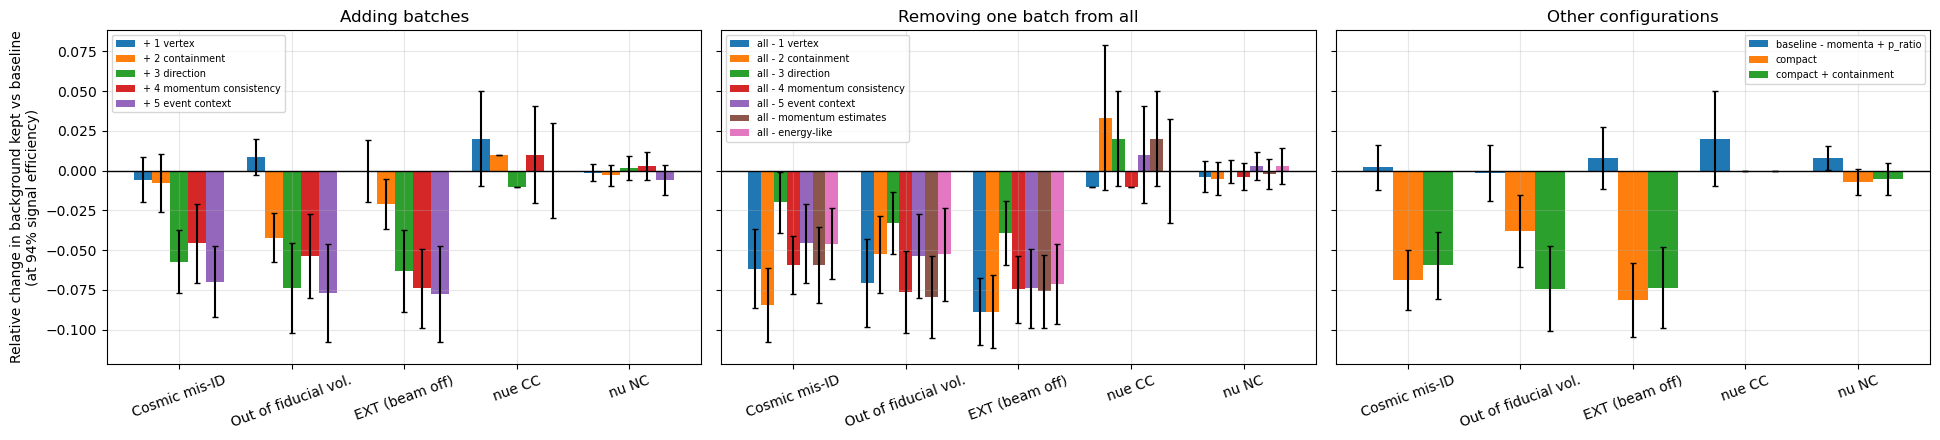

In [28]:
# Summary tables. Values are the mean over seeds; "seed spread" is their standard deviation;
# "Δ ± SE" is the change from the baseline with its paired-bootstrap uncertainty (first seed).
# A change is worth believing if it is larger than about 2 SE and larger than the seed spread.
def fmt(v, e, digits=4):
    return f"{v:+.{digits}f} ± {e:.{digits}f}"

names_done = list(fs_results)
# How many (weighted) validation events each category has: changes for tiny categories are meaningless
print("Weighted validation events per category:",
      {fs_names[c]: round(float(w_val[cat_val == c].sum()), 1) for c in fs_order})
base_mean = fs_results["baseline"]["per_seed"].mean()
deltas = {n: paired_delta(n) for n in names_done if n != "baseline"}

# 1. Overall
rows = []
for n in names_done:
    ps = fs_results[n]["per_seed"]
    row = {"configuration": n, "features": len(fs_results[n]["features"]),
           "trees (mean)": int(np.mean(fs_results[n]["trees"])),
           "AUC": f"{ps['AUC'].mean():.4f}", "AUC seed spread": f"{ps['AUC'].std():.4f}"}
    if n != "baseline":
        for k in ["AUC", "log loss", f"background kept @{FS_EFFS[-1]:.0%}", f"signal eff E<{LOW_E} GeV @{FS_EFFS[-1]:.0%}"]:
            row["Δ " + k] = fmt(ps[k].mean() - base_mean[k], deltas[n][k])
    rows.append(row)
print("Overall")
display(pd.DataFrame(rows).set_index("configuration"))

# 2. Fraction of each category kept, at each fixed signal efficiency
for eff in FS_EFFS:
    rows = []
    for n in names_done:
        ps = fs_results[n]["per_seed"]
        row = {"configuration": n}
        for c in BKG_CATS:
            k = f"{fs_names[c]} kept @{eff:.0%}"
            row[fs_names[c]] = f"{ps[k].mean():.3f}" if n == "baseline" else fmt(ps[k].mean() - base_mean[k], deltas[n][k], 3)
        row["purity"] = f"{ps[f'purity @{eff:.0%}'].mean():.3f}"
        rows.append(row)
    print(f"Fraction of each background kept at {eff:.0%} signal efficiency (baseline: value; others: change)")
    display(pd.DataFrame(rows).set_index("configuration"))

# 3. Separation of signal from each background on its own
rows = []
for n in names_done:
    ps = fs_results[n]["per_seed"]
    row = {"configuration": n}
    for c in BKG_CATS:
        k = f"AUC vs {fs_names[c]}"
        row[fs_names[c]] = f"{ps[k].mean():.4f}" if n == "baseline" else fmt(ps[k].mean() - base_mean[k], deltas[n][k])
    rows.append(row)
print("AUC of signal vs each background (baseline: value; others: change)")
display(pd.DataFrame(rows).set_index("configuration"))

# Background kept at the working point, by category, relative to the baseline
# (left: batches added cumulatively; right: everything minus one batch)
eff = FS_EFFS[-1]
groups = [("Adding batches", [n for n in names_done if n.startswith("+")]),
          ("Removing one batch from all", [n for n in names_done if n.startswith("all")]),
          ("Other configurations", [n for n in names_done if n != "baseline" and not n.startswith(("+", "all"))])]
groups = [g for g in groups if g[1]]
from matplotlib.ticker import PercentFormatter
for title, group in groups:
    fig, ax = plt.subplots(figsize=(13, 5.5))
    width = 0.8 / max(len(group), 1)
    for i, n in enumerate(group):
        rel = [fs_results[n]["per_seed"][f"{fs_names[c]} kept @{eff:.0%}"].mean() / base_mean[f"{fs_names[c]} kept @{eff:.0%}"] - 1
               for c in BKG_CATS]
        err = [deltas[n][f"{fs_names[c]} kept @{eff:.0%}"] / base_mean[f"{fs_names[c]} kept @{eff:.0%}"] for c in BKG_CATS]
        ax.bar(np.arange(len(BKG_CATS)) + i * width, rel, width, yerr=err, capsize=3,
               color=plt.cm.tab10(i % 10), label=n)
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(np.arange(len(BKG_CATS)) + width * (len(group) - 1) / 2)
    ax.set_xticklabels([fs_labels[c] for c in BKG_CATS], rotation=15)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_ylabel("Change in background kept\n(relative to baseline)")
    ax.set_title(f"{title} (at {eff:.0%} signal efficiency)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

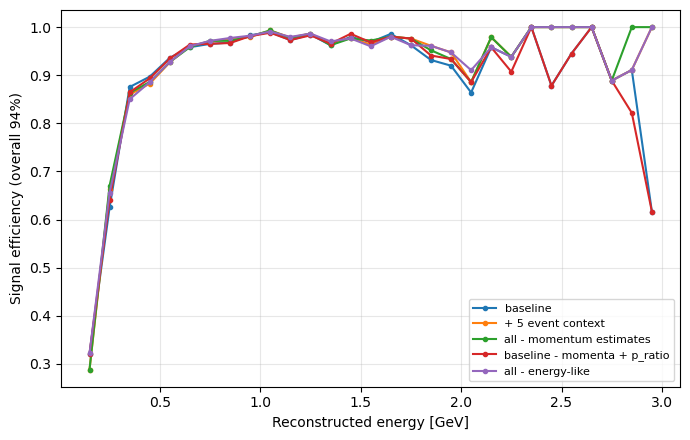

In [14]:
# Signal efficiency against reconstructed energy at the working point: does a configuration make the
# low-energy efficiency better or worse? Edit COMPARE to choose which configurations to overlay.
COMPARE = ["baseline", f"+ {list(FEATURE_BATCHES)[-1]}", "all - momentum estimates",
           "all - energy-like", "compact", "compact + containment"]
eff = FS_EFFS[-1]
ebins_fs = np.linspace(0, 3, 31)
ecent_fs = (ebins_fs[:-1] + ebins_fs[1:]) / 2
sig = y_val == 1

plt.figure(figsize=(12, 5.5))
for n in [c for c in COMPARE if c in fs_results]:
    s = fs_results[n]["scores"][0]
    order = np.argsort(-s[sig])
    cum = np.cumsum(w_val[sig][order]) / w_val[sig].sum()
    thr = s[sig][order][min(np.searchsorted(cum, eff), sig.sum() - 1)]
    h_all, _ = np.histogram(E_val[sig], bins=ebins_fs, weights=w_val[sig])
    h_cut, _ = np.histogram(E_val[sig & (s >= thr)], bins=ebins_fs, weights=w_val[sig & (s >= thr)])
    plt.plot(ecent_fs, np.divide(h_cut, h_all, out=np.full_like(h_all, np.nan), where=h_all > 0), "o-", ms=5, label=n)
plt.xlabel("Reconstructed energy [GeV]")
plt.ylabel(f"Signal efficiency (overall {eff:.0%})")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

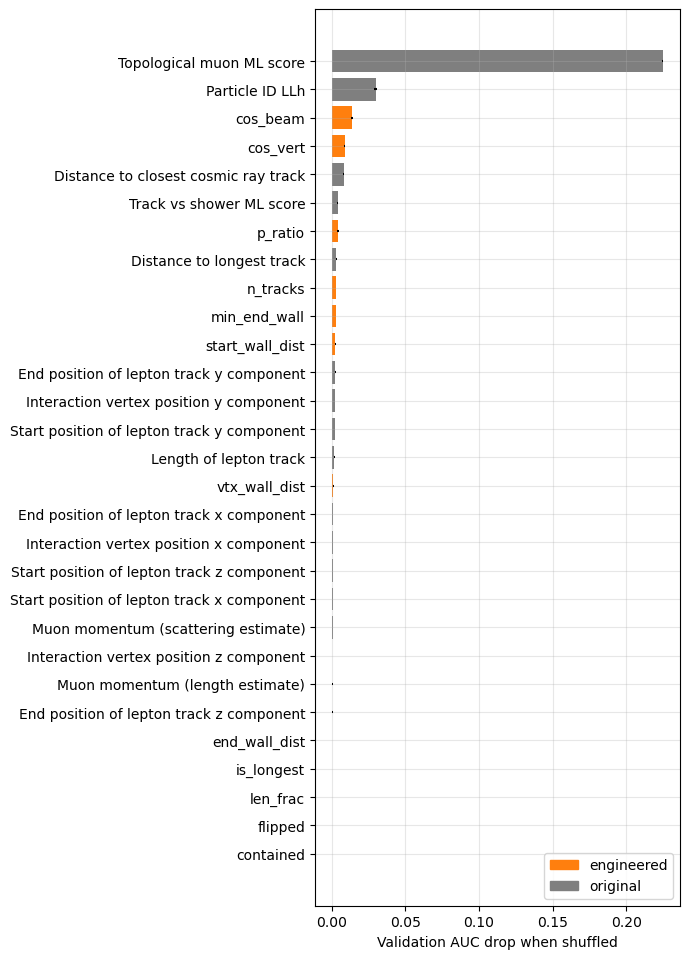

In [15]:
# Permutation importance for one configuration: shuffle one feature at a time in the validation set and
# measure how much the AUC drops. Unlike "gain", this shows what the model actually relies on.
PERM_CONFIG = f"+ {list(FEATURE_BATCHES)[-1]}"   # the configuration with every engineered feature
PERM_REPEATS = 3

res = fs_results[PERM_CONFIG]
Xv = pre[res["features"]].replace([np.inf, -np.inf], np.nan).iloc[fs_val].reset_index(drop=True)
n_trees = res["trees"][0]
base_auc = roc_auc_score(y_val, res["model"].predict_proba(Xv, iteration_range=(0, n_trees))[:, 1], sample_weight=w_val)
perm_rng = np.random.default_rng(1)
drops = {}
for f in res["features"]:
    d = []
    for _ in range(PERM_REPEATS):
        Xp = Xv.copy()
        Xp[f] = perm_rng.permutation(Xp[f].to_numpy())
        d.append(base_auc - roc_auc_score(y_val, res["model"].predict_proba(Xp, iteration_range=(0, n_trees))[:, 1],
                                          sample_weight=w_val))
    drops[f] = (np.mean(d), np.std(d))

imp = pd.DataFrame(drops, index=["AUC drop", "spread"]).T.sort_values("AUC drop")
eng = imp.index.isin(ENGINEERED)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, part, title, colour in [(axes[0], imp[~eng], "Original variables", "tab:grey"),
                                (axes[1], imp[eng], "Engineered features", "tab:orange")]:
    ax.barh([nice(f) for f in part.index], part["AUC drop"], xerr=part["spread"], color=colour)
    ax.set_xlabel("Validation AUC drop when shuffled")
    ax.set_title(title)
    ax.grid(alpha=0.3)
fig.suptitle(f"Permutation importance ('{PERM_CONFIG}')")
plt.tight_layout()
plt.show()

Removing original features

Starting from the chosen set (`compact + containment`), remove groups of features and measure each change against the chosen set (not the baseline). Features are removed in groups because correlated features hide each other: if two carry the same information, removing either one alone costs nothing, but removing both can cost a lot. The aim is a simpler model that depends on fewer things the simulation might get wrong, not a higher AUC.

Run after the compact-set cells (needs `COMPACT` and the harness).

In [31]:
# The chosen set, and the groups of features to try removing from it
CHOSEN = COMPACT + ["min_end_wall", "start_wall_dist"]
REF = "compact + containment"                     # same features as CHOSEN, already trained above
X_COORDS = [START[0], END[0], VERTEX[0]]           # x = the drift direction, hardest to simulate
Y_COORDS = [START[1], END[1], VERTEX[1]]
Z_COORDS = [START[2], END[2], VERTEX[2]]

REMOVAL_GROUPS = {
    "raw start position": START,
    "raw end position": END,
    "raw vertex position": VERTEX,
    "all raw coordinates": START + END + VERTEX,
    "raw x coordinates": X_COORDS,
    "raw y coordinates": Y_COORDS,
    "raw z coordinates": Z_COORDS,
    "track length": [LENGTH],
    "vertex-to-track distance": ["Distance to longest track"],
    "distance to closest cosmic": ["Distance to closest cosmic ray track"],
    "track vs shower score": ["Track vs shower ML score"],
    "n_tracks": ["n_tracks"],                      # engineered, but clearly mismodelled: is it worth keeping?
}
assert all(f in CHOSEN for g in REMOVAL_GROUPS.values() for f in g), "every feature removed must be in CHOSEN"
print(f"Chosen set: {len(CHOSEN)} features; {len(REMOVAL_GROUPS)} removal tests")

Chosen set: 20 features; 12 removal tests


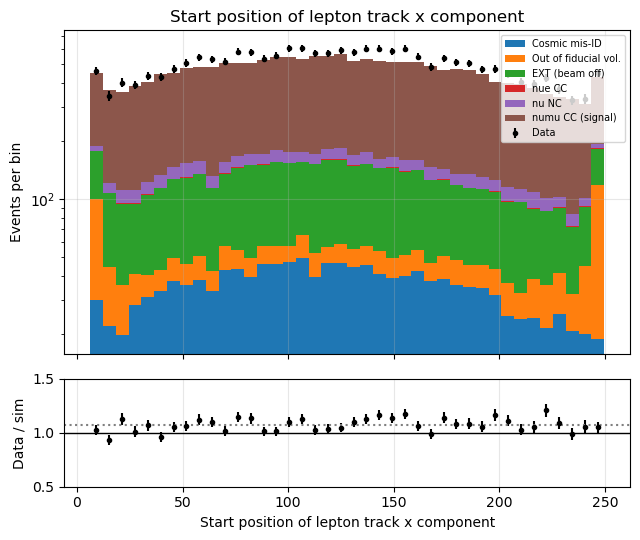

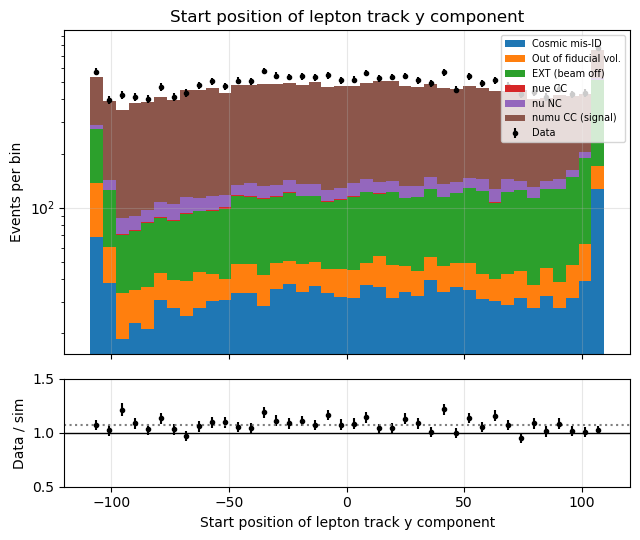

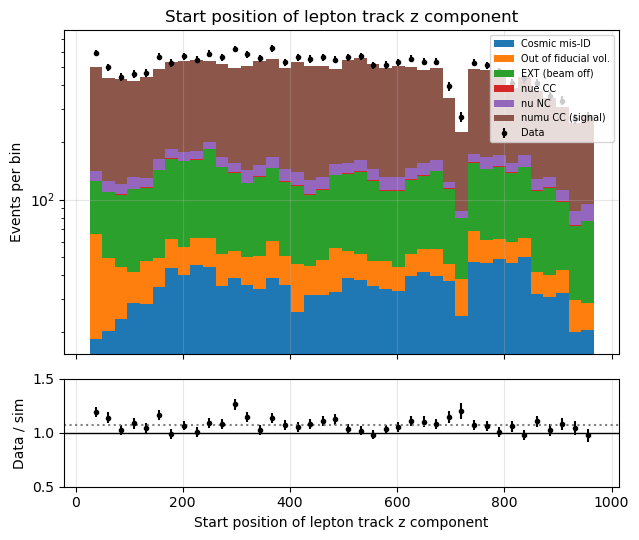

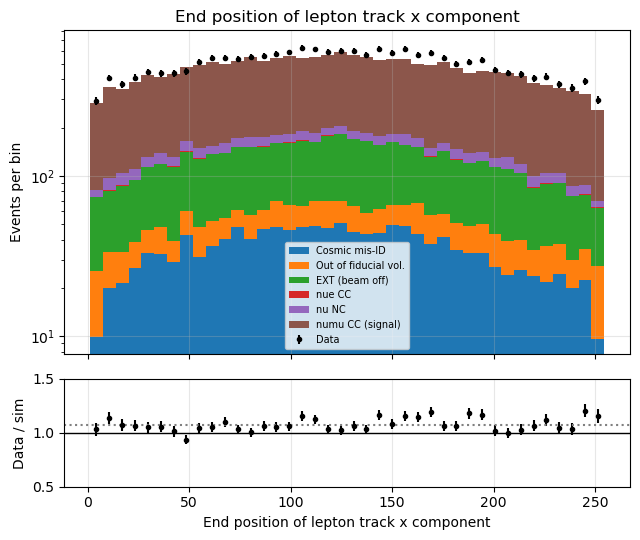

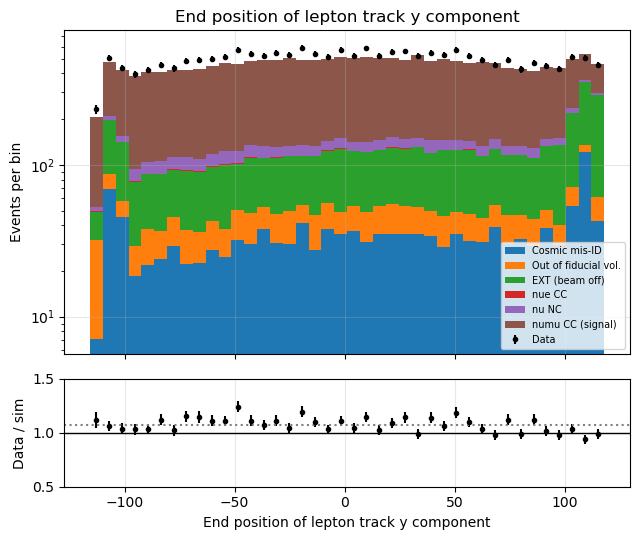

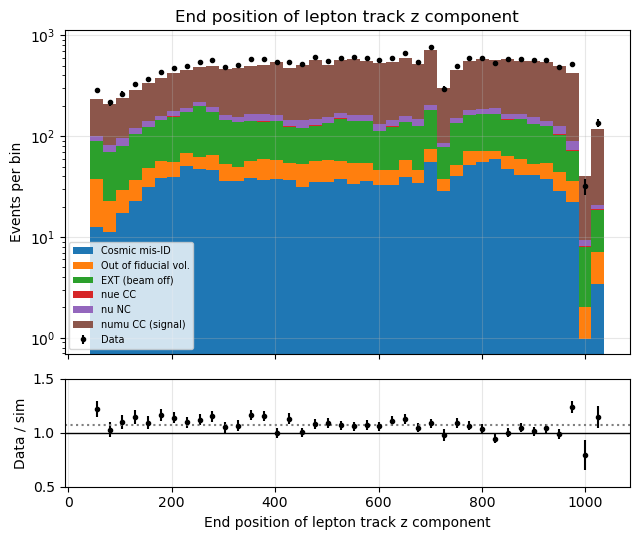

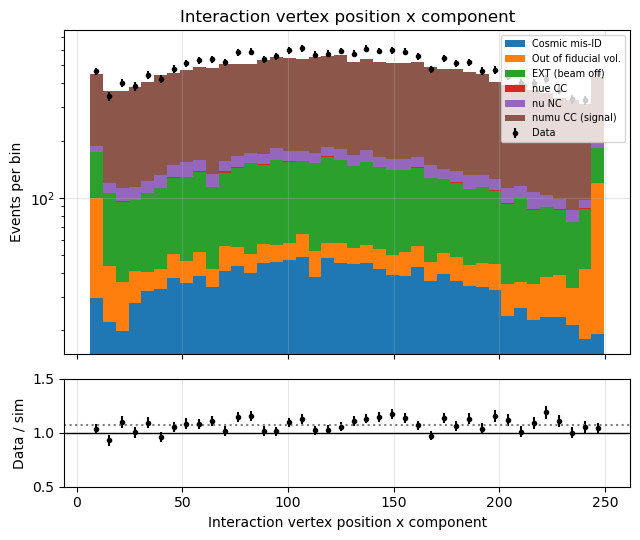

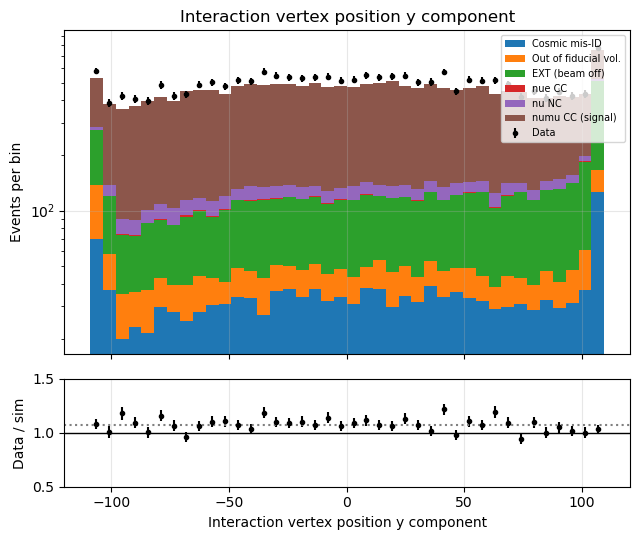

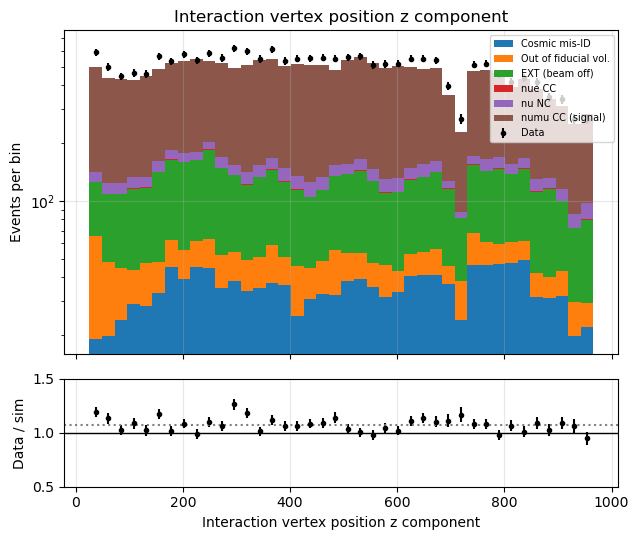

In [32]:
# Data vs simulation for the raw coordinates (the main removal candidates)
for feat in START + END + VERTEX:
    plot_data_vs_sim(feat)

In [33]:
# Train every removal (each takes len(FS_SEEDS) training runs; this is the slow cell)
run_config(REF, CHOSEN)   # reuses the stored result
for group, feats in REMOVAL_GROUPS.items():
    name = f"chosen - {group}"
    if name not in fs_results:
        run_config(name, [f for f in CHOSEN if f not in feats])

compact + containment: same features as 'compact + containment', reusing
chosen - raw start position: 17 features, trees [496, 471, 521], AUC 0.8884 ± 0.0003 (seed spread)
chosen - raw end position: 17 features, trees [427, 436, 420], AUC 0.8866 ± 0.0002 (seed spread)
chosen - raw vertex position: 17 features, trees [506, 491, 477], AUC 0.8880 ± 0.0002 (seed spread)
chosen - all raw coordinates: 11 features, trees [348, 334, 358], AUC 0.8806 ± 0.0003 (seed spread)
chosen - raw x coordinates: 17 features, trees [433, 426, 425], AUC 0.8865 ± 0.0002 (seed spread)
chosen - raw y coordinates: 17 features, trees [437, 445, 435], AUC 0.8852 ± 0.0002 (seed spread)
chosen - raw z coordinates: 17 features, trees [431, 468, 485], AUC 0.8873 ± 0.0003 (seed spread)
chosen - track length: 19 features, trees [420, 469, 460], AUC 0.8869 ± 0.0007 (seed spread)
chosen - vertex-to-track distance: 19 features, trees [407, 421, 448], AUC 0.8865 ± 0.0005 (seed spread)
chosen - distance to closest cosmic: 19

Changes relative to 'compact + containment' at 94% signal efficiency


,features,seed spread,Δ AUC,Δ background kept,Δ Cosmic mis-ID kept,Δ Out of fiducial vol. kept,Δ EXT (beam off) kept,Δ nu NC kept,Δ signal eff E<0.5 GeV
configuration,,,,,,,,,
chosen - raw start position,17,0.0003,-0.0001 ± 0.0002,+0.004 ± 0.005,+0.002 ± 0.006,+0.010 ± 0.009,+0.004 ± 0.006,+0.004 ± 0.006,+0.004 ± 0.003
chosen - raw end position,17,0.0002,-0.0019 ± 0.0003,+0.006 ± 0.005,+0.003 ± 0.007,+0.008 ± 0.009,+0.006 ± 0.007,+0.009 ± 0.007,+0.003 ± 0.003
chosen - raw vertex position,17,0.0002,-0.0005 ± 0.0003,+0.003 ± 0.005,+0.002 ± 0.006,+0.017 ± 0.011,+0.002 ± 0.006,+0.001 ± 0.007,+0.002 ± 0.003
chosen - all raw coordinates,11,0.0003,-0.0079 ± 0.0007,+0.025 ± 0.006,+0.019 ± 0.007,+0.058 ± 0.014,+0.026 ± 0.007,+0.009 ± 0.007,+0.004 ± 0.004
chosen - raw x coordinates,17,0.0002,-0.0020 ± 0.0004,+0.007 ± 0.005,-0.002 ± 0.006,+0.046 ± 0.013,+0.006 ± 0.007,+0.002 ± 0.007,+0.001 ± 0.003
chosen - raw y coordinates,17,0.0002,-0.0032 ± 0.0004,+0.012 ± 0.005,+0.014 ± 0.006,+0.019 ± 0.012,+0.010 ± 0.007,+0.009 ± 0.007,+0.003 ± 0.004
chosen - raw z coordinates,17,0.0003,-0.0012 ± 0.0004,+0.004 ± 0.006,+0.002 ± 0.007,-0.002 ± 0.011,+0.006 ± 0.008,+0.006 ± 0.007,+0.002 ± 0.003
chosen - track length,19,0.0007,-0.0016 ± 0.0003,+0.008 ± 0.005,+0.004 ± 0.006,+0.013 ± 0.010,+0.008 ± 0.006,+0.010 ± 0.006,-0.002 ± 0.003
chosen - vertex-to-track distance,19,0.0005,-0.0020 ± 0.0004,+0.006 ± 0.005,-0.000 ± 0.008,+0.032 ± 0.012,+0.005 ± 0.006,+0.004 ± 0.006,+0.005 ± 0.003


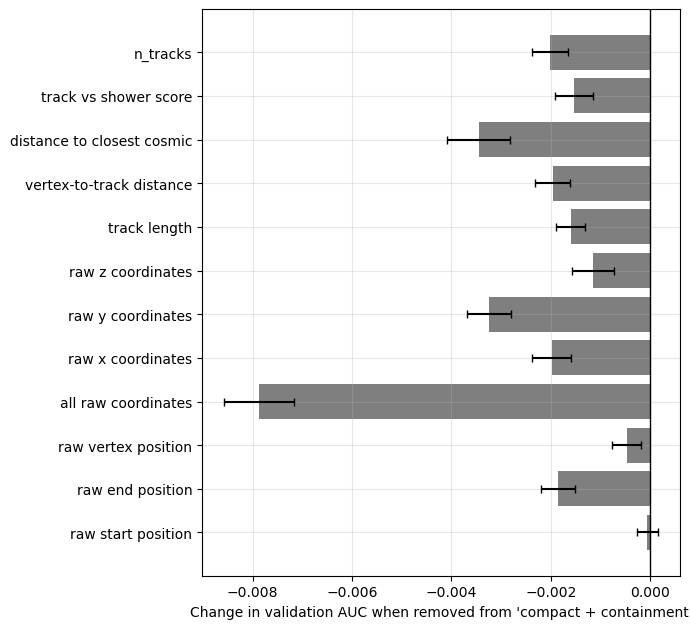

In [34]:
# Every removal compared with the chosen set, using the paired bootstrap against it.
# Negative ΔAUC / positive Δ background kept = removing the group hurts. A group can be dropped if all its
# changes are within about 2 SE of zero. (nue CC is left out: too few events to say anything.)
def compare_to(ref, names, eff=FS_EFFS[-1]):
    ref_mean = fs_results[ref]["per_seed"].mean()
    keys = ([("AUC", "AUC", 4), (f"background kept @{eff:.0%}", "background kept", 3)]
            + [(f"{fs_names[c]} kept @{eff:.0%}", fs_names[c] + " kept", 3) for c in BKG_CATS if c != 10]
            + [(f"signal eff E<{LOW_E} GeV @{eff:.0%}", f"signal eff E<{LOW_E} GeV", 3)])
    rows = []
    for n in names:
        mean, se = fs_results[n]["per_seed"].mean(), paired_delta(n, base=ref)
        row = {"configuration": n, "features": len(fs_results[n]["features"]),
               "seed spread": f"{fs_results[n]['per_seed']['AUC'].std():.4f}"}
        for k, label, digits in keys:
            row["Δ " + label] = fmt(mean[k] - ref_mean[k], se[k], digits)
        rows.append(row)
    return pd.DataFrame(rows).set_index("configuration")

removal_names = [f"chosen - {g}" for g in REMOVAL_GROUPS if f"chosen - {g}" in fs_results]
print(f"Changes relative to '{REF}' at {FS_EFFS[-1]:.0%} signal efficiency")
display(compare_to(REF, removal_names))

# ΔAUC of each removal, with its uncertainty: bars to the left of zero mean the group was doing something
d = [fs_results[n]["per_seed"]["AUC"].mean() - fs_results[REF]["per_seed"]["AUC"].mean() for n in removal_names]
e = [paired_delta(n, base=REF)["AUC"] for n in removal_names]
from matplotlib.ticker import MaxNLocator
plt.figure(figsize=(11, 0.5 * len(removal_names) + 1.5))
plt.barh([n.replace("chosen - ", "").replace("n_tracks", "tracks in event") for n in removal_names], d, xerr=e,
         color="tab:grey", capsize=3)
plt.gca().xaxis.set_major_locator(MaxNLocator(5))
plt.axvline(0, color="black", lw=1)
plt.xlabel("Change in validation AUC when removed")
plt.title(f"Removing features from '{REF}'")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Does the selection behave the same on real data? (data-agreement test)

A feature the simulation describes imperfectly only matters if it makes the BDT select real data differently from simulation. For each model below, at the threshold giving 94% signal efficiency on simulation:

- **pass fraction**: the fraction of preselected events passing the cut, in real data and in simulation (fractions, so the ~8% normalisation difference cancels). Their difference is not expected to be zero - the data has a different mix of events - but a feature whose mismodelling leaks into the selection would *change* it.
- **score shape χ²/ndf**: how well the shape of the BDT score distribution agrees between data and simulation (after normalising to the same total); ≈ 1 means agreement within statistics.

The column to judge by is the change relative to `final`, with a paired bootstrap over both the data and the simulation events.

In [35]:
# The recommended final set and the variants to compare it with
FINAL = [f for f in CHOSEN if f not in START]          # chosen set without the raw start position (17 features)
AGREE_CONFIGS = {
    "baseline": BASE,
    REF: CHOSEN,
    "final": FINAL,
    "final - n_tracks": [f for f in FINAL if f != "n_tracks"],
    "final - raw x coordinates": [f for f in FINAL if f not in X_COORDS],
}
for name, feats in AGREE_CONFIGS.items():
    if name not in fs_results:
        run_config(name, feats)
print("final:", len(FINAL), "features:", FINAL)

final: same features as 'chosen - raw start position', reusing
final - n_tracks: 16 features, trees [421, 471, 445], AUC 0.8861 ± 0.0006 (seed spread)
final - raw x coordinates: 15 features, trees [438, 438, 424], AUC 0.8865 ± 0.0002 (seed spread)
final: 17 features: ['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'cos_beam', 'cos_vert', 'n_tracks', 'min_end_wall', 'start_wall_dist']


Data vs simulation at 94% signal efficiency (threshold set on simulation for each model)


,features,sim pass,data pass,data - sim,change vs final,score shape χ²/ndf
configuration,,,,,,
baseline,17,0.781,0.784,+0.0028 ± 0.0049,+0.0047 ± 0.0020,54/38 = 1.42
compact + containment,20,0.775,0.771,-0.0030 ± 0.0048,-0.0011 ± 0.0012,52/38 = 1.37
final,17,0.775,0.774,-0.0019 ± 0.0048,—,56/38 = 1.48
final - n_tracks,16,0.776,0.776,-0.0003 ± 0.0048,+0.0016 ± 0.0015,69/38 = 1.83
final - raw x coordinates,15,0.777,0.774,-0.0026 ± 0.0048,-0.0007 ± 0.0015,55/38 = 1.44


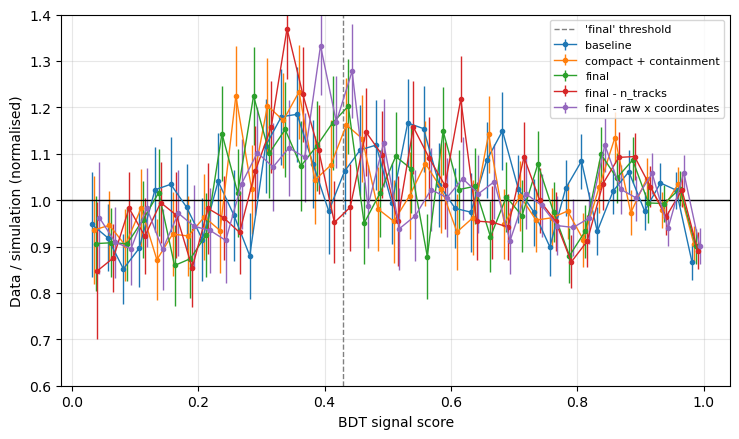

In [36]:
# Score the preselected real data with each model and compare it with the validation simulation
AG_EFF = FS_EFFS[-1]
ag_rng = np.random.default_rng(2)
AG_BOOT = [(ag_rng.integers(0, len(fs_val), len(fs_val)), ag_rng.integers(0, len(data_fs), len(data_fs)))
           for _ in range(FS_N_BOOT)]                    # resample simulation and data events together
sbins_ag = np.linspace(0, 1, 41)
scent_ag = (sbins_ag[:-1] + sbins_ag[1:]) / 2

def data_scores(name):
    """BDT score of every preselected real event, from the configuration's first-seed model."""
    res = fs_results[name]
    Xd = data_fs[res["features"]].replace([np.inf, -np.inf], np.nan)
    return res["model"].predict_proba(Xd, iteration_range=(0, res["trees"][0]))[:, 1]

def working_threshold(s, eff):
    """Score threshold keeping this fraction of the weighted validation signal."""
    sig = y_val == 1
    order = np.argsort(-s[sig])
    cum = np.cumsum(w_val[sig][order]) / w_val[sig].sum()
    return s[sig][order][min(np.searchsorted(cum, eff), sig.sum() - 1)]

agree = {}
for name in AGREE_CONFIGS:
    s_sim, s_dat = fs_results[name]["scores"][0], data_scores(name)
    thr = working_threshold(s_sim, AG_EFF)

    def pass_fractions(i_sim=slice(None), i_dat=slice(None)):
        ss, ww, sd = s_sim[i_sim], w_val[i_sim], s_dat[i_dat]
        return np.mean(sd >= thr), ww[ss >= thr].sum() / ww.sum()

    dat_pass, sim_pass = pass_fractions()
    boot = np.array([np.subtract(*pass_fractions(i, j)) for i, j in AG_BOOT])   # data - simulation, resampled

    # Shape of the score distribution: simulation normalised to the data total
    hs, _ = np.histogram(s_sim, sbins_ag, weights=w_val)
    hs2, _ = np.histogram(s_sim, sbins_ag, weights=w_val ** 2)
    hd, _ = np.histogram(s_dat, sbins_ag)
    k = hd.sum() / hs.sum()
    var = hd + k ** 2 * hs2
    ok = var > 0
    agree[name] = {"threshold": thr, "data pass": dat_pass, "sim pass": sim_pass, "boot": boot,
                   "chi2": np.sum((hd - k * hs)[ok] ** 2 / var[ok]), "ndf": ok.sum() - 1,
                   "ratio": np.where(ok, hd / np.where(hs > 0, k * hs, np.nan), np.nan),
                   "ratio err": np.where(ok, np.sqrt(var) / np.where(hs > 0, k * hs, np.nan), np.nan)}

rows = []
for name, a in agree.items():
    d = a["data pass"] - a["sim pass"]
    d_ref = agree["final"]["data pass"] - agree["final"]["sim pass"]
    rows.append({"configuration": name, "features": len(AGREE_CONFIGS[name]),
                 "sim pass": f"{a['sim pass']:.3f}", "data pass": f"{a['data pass']:.3f}",
                 "data - sim": f"{d:+.4f} ± {a['boot'].std():.4f}",
                 "change vs final": "—" if name == "final" else f"{d - d_ref:+.4f} ± {(a['boot'] - agree['final']['boot']).std():.4f}",
                 "score shape χ²/ndf": f"{a['chi2']:.0f}/{a['ndf']} = {a['chi2'] / a['ndf']:.2f}"})
print(f"Data vs simulation at {AG_EFF:.0%} signal efficiency (threshold set on simulation for each model)")
display(pd.DataFrame(rows).set_index("configuration"))

# Data / simulation ratio of the score distribution (normalised): flat = the BDT behaves the same on both
fig, ax = plt.subplots(figsize=(12.5, 6))
for i, (name, a) in enumerate(agree.items()):
    ax.errorbar(scent_ag + (i - 2) * 0.003, a["ratio"], yerr=a["ratio err"], fmt="o-", ms=5, lw=1.5,
                color=plt.cm.tab10(i), label=name)
ax.axhline(1, color="black", lw=1)
ax.axvline(agree["final"]["threshold"], color="grey", ls="--", lw=1.5, label="'final' threshold")
ax.set_ylim(0.6, 1.4)
ax.set_xlabel("BDT signal score")
ax.set_ylabel("Data / simulation (normalised)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# BDT pass fractions, data vs simulation, for EVERY configuration trained so far (run after the
# data-agreement cell above, which defines data_scores, working_threshold and the bootstrap resamples).
# At each model's own 94%-signal-efficiency threshold: fraction of preselected events passing in the validation
# simulation and in real data, their difference, the change in that difference relative to the baseline
# (paired bootstrap), and the data-vs-simulation shape chi^2/ndf of the BDT score.
def pass_comparison(name):
    s_sim, s_dat = fs_results[name]["scores"][0], data_scores(name)
    thr = working_threshold(s_sim, AG_EFF)
    def diff(i_sim=slice(None), i_dat=slice(None)):
        ss, ww = s_sim[i_sim], w_val[i_sim]
        return np.mean(s_dat[i_dat] >= thr) - ww[ss >= thr].sum() / ww.sum()
    hs, _ = np.histogram(s_sim, sbins_ag, weights=w_val)
    hs2, _ = np.histogram(s_sim, sbins_ag, weights=w_val ** 2)
    hd, _ = np.histogram(s_dat, sbins_ag)
    k = hd.sum() / hs.sum()
    var = hd + k ** 2 * hs2
    ok = var > 0
    return {"sim pass": w_val[s_sim >= thr].sum() / w_val.sum(), "data pass": np.mean(s_dat >= thr),
            "diff": diff(), "boot": np.array([diff(i, j) for i, j in AG_BOOT]),
            "shape chi2/ndf": np.sum((hd - k * hs)[ok] ** 2 / var[ok]) / (ok.sum() - 1)}

pass_results = {n: pass_comparison(n) for n in fs_results}
base_pc = pass_results["baseline"]
rows = []
for n, r in pass_results.items():
    rows.append({"configuration": n, "features": len(fs_results[n]["features"]),
                 "sim pass": f"{r['sim pass']:.3f}", "data pass": f"{r['data pass']:.3f}",
                 "data - sim": f"{r['diff']:+.4f} ± {r['boot'].std():.4f}",
                 "change vs baseline": "—" if n == "baseline" else
                     f"{r['diff'] - base_pc['diff']:+.4f} ± {(r['boot'] - base_pc['boot']).std():.4f}",
                 "score shape χ²/ndf": f"{r['shape chi2/ndf']:.2f}"})
print(f"Pass fractions at {AG_EFF:.0%} signal efficiency (threshold set on simulation for each model)")
display(pd.DataFrame(rows).set_index("configuration"))

Pass fractions at 94% signal efficiency (threshold set on simulation for each model)


,features,sim pass,data pass,data - sim,change vs baseline,score shape χ²/ndf
configuration,,,,,,
baseline,17,0.781,0.784,+0.0028 ± 0.0049,—,1.42
+ 1 vertex,18,0.781,0.784,+0.0025 ± 0.0048,-0.0003 ± 0.0012,1.38
+ 2 containment,23,0.778,0.780,+0.0020 ± 0.0049,-0.0007 ± 0.0015,1.36
+ 3 direction,25,0.775,0.778,+0.0025 ± 0.0047,-0.0002 ± 0.0019,1.77
+ 4 momentum consistency,26,0.775,0.775,-0.0003 ± 0.0046,-0.0031 ± 0.0020,1.82
+ 5 event context,29,0.773,0.773,-0.0006 ± 0.0049,-0.0033 ± 0.0020,2.06
all - 1 vertex,28,0.773,0.771,-0.0021 ± 0.0048,-0.0049 ± 0.0021,1.59
all - 2 containment,24,0.774,0.775,+0.0005 ± 0.0046,-0.0022 ± 0.0021,1.24
all - 3 direction,27,0.778,0.779,+0.0001 ± 0.0049,-0.0026 ± 0.0018,1.20


# Feature study: summary of results

*Numbers from the full run with the Optuna hyperparameters tuned on the original features. ΔAUC uncertainties come from the paired bootstrap (200 resamples of the validation events); "seed spread" is the standard deviation over 3 training seeds. A change counts as real if it exceeds about 2× its uncertainty and the seed spread. νe CC has only about 6 weighted validation events, so its numbers are noise and are ignored.*

## Method

- **Training:** every configuration uses the same hyperparameters and the same train/validation split. 10% of the training events are held back for early stopping, with the 1-SE tree count. Each configuration is evaluated only on the validation split, with 3 seeds.
- **Metrics:** AUC and log loss; background kept at fixed 90% and 94% signal efficiency, **per background category**; AUC of signal against each background separately; low-energy (<0.5 GeV) signal efficiency; permutation importance.
- **Modelling checks:** a data-vs-simulation plot for each feature. The selection-level check (data vs simulation pass fractions) decides whether a mismodelled feature matters.

## Adding the engineered batches (baseline: 17 original features, AUC 0.8785 ± 0.0003)

| Batch added (cumulative) | ΔAUC vs baseline | Verdict |
|---|---|---|
| 1 vertex (`flipped`) | −0.0002 ± 0.0002 | No effect: only 0.7% of tracks are flipped |
| 2 containment (5 wall-distance features) | +0.0004 ± 0.0004 | Overall nothing, but helps out-of-fiducial-volume (OOFV) events: AUC vs OOFV +0.0064 ± 0.0018 |
| **3 direction (`cos_beam`, `cos_vert`)** | **+0.0082 ± 0.0008** | **The key batch.** At 94% signal efficiency: cosmics kept −2.2 points, OOFV −5.0, EXT −2.0; **AUC vs NC +0.028 ± 0.003**. Ranked 3rd and 4th in permutation importance |
| 4 momentum consistency (`p_ratio`) | +0.0086 (+0.0004 on top) | Marginal |
| 5 event context (`n_tracks`, `len_frac`, `is_longest`) | +0.0106 (+0.0020 on top) | Only `n_tracks` matters; `len_frac` and `is_longest` have zero importance (redundant for trees) |

**Ablation (full set minus one batch):** removing direction costs 0.0077 and event context 0.0020. Removing vertex, containment, momentum consistency, or the two muon momentum estimates costs nothing (within ±0.0005). **The momentum estimates are redundant:** the range estimate is a fixed function of track length, and the rest of their information is already in the other features.

**Energy-like features:** removing the momenta *and* track length costs 0.0016 AUC and makes low-energy signal efficiency *worse* (−0.012 ± 0.004), so track length helps. The efficiency-vs-energy curves are almost identical for every configuration: the steep turn-on below about 0.4 GeV is physics (15–40 cm muon tracks look like protons and cosmic fragments), not feature-driven sculpting.

## Compact sets

| Set | Features | AUC | Notes |
|---|---|---|---|
| Full (all batches) | 29 | 0.8891 | |
| `compact` (originals − momenta + `cos_beam`, `cos_vert`, `n_tracks`) | 18 | 0.8877 | Loses about half the OOFV improvement |
| **`compact + containment`** (+ `min_end_wall`, `start_wall_dist`) | **20** | **0.8885** | Matches the full set at the working point (background kept, purity, every category); only signal-vs-NC AUC is slightly lower (+0.029 vs +0.033), which is `p_ratio`'s contribution |

## Removing original features (relative to `compact + containment`)

- **Raw start position:** removable (−0.0001 ± 0.0002). The track starts at the vertex, so it duplicates the vertex position.
- **Every other group costs 0.0012–0.0035 AUC (3–8σ):**
  - distance to closest cosmic (−0.0035; cosmics and EXT);
  - raw y coordinates (−0.0032; cosmics);
  - raw x coordinates (−0.0020; OOFV; x is the drift direction);
  - vertex-to-track distance (−0.0020; OOFV);
  - `n_tracks` (−0.0020);
  - raw end position (−0.0019);
  - track length (−0.0016);
  - track-vs-shower score (−0.0015);
  - raw z coordinates (−0.0012).
- **Removing all 9 raw coordinates together costs −0.0079.** Correlated features hide each other, so removals must be tested in groups.
- These costs are statistically clear but small in absolute terms (0.1–0.3% AUC). Next to the 15% per-bin systematic, the choice is about simplicity and robustness rather than performance.

## Does the simulation model the features?

- **Shape χ²/ndf** (data vs simulation, normalised; about 1 = agreement within statistics):

  | Feature | χ²/ndf |
  |---|---|
  | `cos_vert` | 0.9 |
  | PID LLh | 1.2 |
  | `cos_beam`, `start_wall_dist` | 1.5 |
  | track length, range momentum | 1.7 |
  | `min_end_wall` | 1.9 |
  | scattering momentum | 2.2 |
  | topological score | 2.9 |
  | **`p_ratio`** | **4.6** |
  | **`n_tracks`** | **7.4** |

- **`p_ratio`:** in data the two momentum estimates agree more tightly (central 68% width 0.129 vs 0.140 in simulation), so the simulation probably mismodels the scattering method's per-event precision. Each momentum estimate on its own is modelled reasonably well.
- **`n_tracks`:** the simulation has relatively too many multi-track events. Deviations reach about 8% at 3 tracks and about 15% at 4.
- **At high statistics, χ² flags small but real differences.** Whether one matters is decided by the selection-level test:
  - pass fractions at 94% signal efficiency agree between data and simulation within ±0.005 for every model;
  - removing `n_tracks` (+0.0016 ± 0.0015) or the raw x coordinates (−0.0007 ± 0.0015) **does not change** the data/simulation agreement;
  - the new features shift it by only 0.5% relative to the baseline;
  - the BDT score's shape χ²/ndf is about 1.4 for every model, with the same pattern for all (so it comes from the data, not from the features).
- **Conclusion:** `n_tracks` and the raw x coordinates are safe to keep. `p_ratio` is dropped: a tiny gain plus the worst modelling of the useful features.

## Final feature set (17 features; now used in `Task_2-.ipynb`)

- **Original:** topological muon score, Particle ID LLh, track-vs-shower score, distance to closest cosmic, vertex-to-track distance ("Distance to longest track"), track length, vertex x/y/z, track end x/y/z.
- **Engineered:** `cos_beam`, `cos_vert`, `n_tracks`, `min_end_wall`, `start_wall_dist`.
- **Removed from the original 17:** both muon momentum estimates (redundant) and raw start x/y/z (duplicates the vertex).
- **Performance:** AUC 0.8884 (full set 0.8891, baseline 0.8785), i.e. about 99% of the full set's gain with 12 fewer features. Purity at 94% signal efficiency rises from 0.820 to 0.828; cosmic, OOFV and EXT backgrounds fall by 5–8% relative.
- **Side effect:** about 1% lower low-energy signal efficiency at fixed 94% overall efficiency (from the direction features).

## Caveats and next steps

- **Single training run on one validation split.** Picking the best of many configurations makes the winner slightly optimistic. The final judgement is the full pipeline: re-run Optuna for the new features (warm start, 40 trials), the k-fold, and the **expected exclusion contour** with and without the new features.
- **Hyperparameters were tuned on the original feature set**, and the same values were used for every comparison.
- **The improvements are real but modest.** With the 15% systematic dominating the χ², the effect on the exclusion contour may be small.